In [8]:
# RUNTIME & INPUT DATASET PATHS — update this cell when switching Kaggle/Colab or changing Kaggle inputs.
from pathlib import Path

RUNTIME = "kaggle"  # "kaggle" or "colab"
if RUNTIME not in {"kaggle", "colab"}:
    raise ValueError("RUNTIME must be 'kaggle' or 'colab'.")

if RUNTIME == "kaggle":
    # These are the three datasets attached in Kaggle's Input panel.
    VEHIDE_DIR = Path("/kaggle/input/datasets/hendrichscullen/vehide-dataset-automatic-vehicle-damage-detection")
    STANFORD_CARS_DIR = Path("/kaggle/input/datasets/eduardo4jesus/stanford-cars-dataset")
    PREDICTIONS_DIR = Path("/kaggle/input/datasets/sumanthvuppu/predictions")
    WORK_DIR = Path("/kaggle/working")
else:
    # Colab downloads the two source datasets here. Place any uploaded prediction/model files in PREDICTIONS_DIR.
    DATA_ROOT = Path("/content/vehicle_damage_data")
    VEHIDE_DIR = DATA_ROOT / "vehide-dataset-automatic-vehicle-damage-detection"
    STANFORD_CARS_DIR = DATA_ROOT / "stanford-cars-dataset"
    PREDICTIONS_DIR = DATA_ROOT / "predictions"
    WORK_DIR = Path("/content/vehicle_damage_work")

YOLO_DATASET_DIR = WORK_DIR / "yolo_dataset"
RESULTS_DIR = WORK_DIR / "results"
EXPORT_DIR = WORK_DIR / "exports"
NO_DAMAGE_IMAGES_DIR = WORK_DIR / "no_damage_images"
NO_DAMAGE_VAL_IMAGES_DIR = WORK_DIR / "no_damage_images_val"
NO_DAMAGE_ANNOS_DIR = WORK_DIR / "no_damage_annos"
TRAIN_COMBINED_JSON = WORK_DIR / "0Train_combined.json"
VAL_COMBINED_JSON = WORK_DIR / "0Val_combined.json"
DATASET_YAML = WORK_DIR / "dataset.yaml"

for directory in (WORK_DIR, RESULTS_DIR, EXPORT_DIR):
    directory.mkdir(parents=True, exist_ok=True)

print(f"Runtime: {RUNTIME}")
print(f"VehiDE input: {VEHIDE_DIR}")
print(f"Stanford Cars input: {STANFORD_CARS_DIR}")
print(f"Predictions input: {PREDICTIONS_DIR}")
print(f"Working files: {WORK_DIR}")

Runtime: kaggle
VehiDE input: /kaggle/input/datasets/hendrichscullen/vehide-dataset-automatic-vehicle-damage-detection
Stanford Cars input: /kaggle/input/datasets/eduardo4jesus/stanford-cars-dataset
Predictions input: /kaggle/input/datasets/sumanthvuppu/predictions
Working files: /kaggle/working


In [9]:
# Install necessary model architecture modules and libraries:
!pip install kaggle
!pip install ultralytics pyyaml
!pip install xgboost

In [10]:
import os
import json
import time
import torch
import shutil
import random
import joblib
import zipfile
import glob, cv2
import torch.cuda
import numpy as np
import pandas as pd
import torchvision
import torch.nn as nn
import ultralytics
ultralytics.checks()
from glob import glob
from tqdm import tqdm
from ultralytics import YOLO
import torch.optim as optim
from datetime import datetime
import seaborn as sns
from sklearn.metrics import hamming_loss
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.patches import Polygon
from collections import Counter
from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True
import matplotlib.patches as patches
from torchvision import transforms, models
import albumentations as A
import warnings
warnings.filterwarnings("ignore")
from IPython.display import display, HTML
from ultralytics.data.augment import Compose
# from torchvision.references.detection import engine
# from engine import train_one_epoch, evaluate
from torchvision.datasets import CocoDetection
from torch.utils.data import Dataset, DataLoader
# from torchvision.models.detection import FasterRCNN
from torchvision.transforms import v2 as transforms
# from torchvision.models.detection.rpn import AnchorGenerator
# from torchvision.models.detection import fasterrcnn_resnet50_fpn
# from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from sklearn import metrics
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import make_scorer, precision_score, accuracy_score
from sklearn.model_selection import cross_val_score
from sklearn.metrics import f1_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import multilabel_confusion_matrix
from sklearn.metrics import classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.multiclass import OneVsRestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, accuracy_score, f1_score

Ultralytics 8.4.178 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Setup complete ✅ (4 CPUs, 31.3 GB RAM, 7087.0/8156.9 GB disk)


## Import Dataset(Only for Colab):

Comment below cell when not using Colab.

In [4]:
# # Dataset setup
# # Kaggle: attach both datasets in the Input panel, then run this cell to validate them.
# # Colab: upload kaggle.json when prompted; the datasets are downloaded into DATA_ROOT.
# if RUNTIME == "kaggle":
#     for required_dir in (VEHIDE_DIR, STANFORD_CARS_DIR):
#         if not required_dir.is_dir():
#             raise FileNotFoundError(
#                 f"Missing {required_dir}. Attach the required dataset in Kaggle's Input panel."
#             )
#     print("Kaggle input datasets found.")
# else:
#     from google.colab import files
#     DATA_ROOT.mkdir(parents=True, exist_ok=True)
#     files.upload()  # Upload kaggle.json
#     !mkdir -p ~/.kaggle
#     !mv kaggle.json ~/.kaggle/kaggle.json
#     !chmod 600 ~/.kaggle/kaggle.json
#     !kaggle datasets download -d hendrichscullen/vehide-dataset-automatic-vehicle-damage-detection -p {DATA_ROOT}
#     !unzip -qo {DATA_ROOT / 'vehide-dataset-automatic-vehicle-damage-detection.zip'} -d {VEHIDE_DIR}


# # Stanford Cars setup (needed only in Colab; Kaggle reads the attached dataset).
# if RUNTIME == "colab":
#     !kaggle datasets download -d eduardo4jesus/stanford-cars-dataset -p {DATA_ROOT}
#     !unzip -qo {DATA_ROOT / 'stanford-cars-dataset.zip'} "cars_test/*" -d {STANFORD_CARS_DIR / 'cars_train'}
#     source = STANFORD_CARS_DIR / "cars_train" / "cars_test" / "cars_test"
#     destination = STANFORD_CARS_DIR / "cars_train" / "cars_train"
#     destination.parent.mkdir(parents=True, exist_ok=True)
#     shutil.move(str(source), str(destination))
# else:
#     print("Using the attached Kaggle Stanford Cars dataset.")
    

## Define Functions:

In [11]:
# Use GPU for entire notebook:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device: ", device)

notebook_starttime = time.time()

Using device:  cuda


In [12]:
# Visualize Images with Polygon Annotations:

def visualize_images_with_VIAannos(img_dir, annotation_file, num_samples=5, seed=None):
    """
    Visualize images with VIA polygon annotations overlaid.

        img_dir (str): Directory containing the images.
        annotation_file (str): Path to VIA JSON annotations.
        num_samples (int): Number of image samples to visualize.
        seed (int, optional): Random seed for reproducibility.
    """
    # Load Annotation File:
    with open(annotation_file) as f:
        annotations = json.load(f)

    keys = list(annotations.keys())
    if seed is not None:
        random.seed(seed)
    sample_imgs = random.sample(keys, min(num_samples, len(keys)))

    # Visualization:
    for img_name in sample_imgs:
        img_path = os.path.join(img_dir, img_name)
        if not os.path.exists(img_path):
            print("Image not found: ", img_name)
            continue

        # Load sample:
        image = Image.open(img_path).convert("RGB")
        w, h = image.size

        fig, ax = plt.subplots(figsize=(6, 4))
        ax.imshow(image)
        ax.axis("off")
        ax.set_title(img_name)

        # Plot polygon annotations:
        for region in annotations[img_name].get('regions', []):
            all_x = region.get('all_x', [])
            all_y = region.get('all_y', [])
            class_name = region.get('class', 'unknown')

            if len(all_x) < 3 or len(all_x) != len(all_y):
                continue  # Skip incorrectly annotated regions

            points = list(zip(all_x, all_y))
            polygon = Polygon(points, closed=True, edgecolor='red', facecolor='red', alpha=0.3, linewidth=2)
            ax.add_patch(polygon)

            ax.text(all_x[0], all_y[0] - 5, class_name, color='white',
                    fontsize=10, bbox=dict(facecolor='red', alpha=0.7, edgecolor='none'))

        plt.tight_layout()
        plt.show()


# Create JSON Attributes for no_damage class:

def make_via_dict(img_list):
    data = {}
    for fname in img_list:
        data[fname] = {
            "filename": fname,
            "size": -1,  # optional
            "regions": [],  # no damage = no annotation regions
            "file_attributes": {"class": "no_damage"}
        }
    return data


# Merge original and no_damage annotation files:

def merge_jsons(json1_path, json2_path, output_path):
    with open(json1_path) as f1, open(json2_path) as f2:
        data1 = json.load(f1)
        data2 = json.load(f2)

    merged = {**data1, **data2}

    with open(output_path, 'w') as f:
        json.dump(merged, f)


# Check image counts from annotation files:

def check_via_json_stats(json_path, label=""):
    with open(json_path) as f:
        data = json.load(f)

    print("\n", label or os.path.basename(json_path))
    print("Total image entries: ",len(data))

    no_damage_count = sum(
        1 for v in data.values()
        if v.get("file_attributes", {}).get("class") == "no_damage"
    )

    print("no_damage entries: ", no_damage_count)

    class_counter = Counter()

    for item in data.values():
        regions = item.get("regions", [])
        for region in regions:
            cls = region.get("class")
            if cls:
                class_counter[cls] += 1

    class_counter["no_damage"] = no_damage_count
    class_counts_dict = dict(class_counter)

    print("Damage class Instances:")
    for cls, count in class_counter.items():
        print(f"{cls}: {count}")

    # print("Damage entries: ", len(data) - no_damage_count)
    return dict(class_counter)


# Copy iamges from one folder to another

def copy_images(src_dir, dst_dir):
    os.makedirs(dst_dir, exist_ok=True)
    for fname in os.listdir(src_dir):
        if fname.lower().endswith((".jpg", ".jpeg", ".png")):
            shutil.copy(os.path.join(src_dir, fname), os.path.join(dst_dir, fname))



# Clip annotations in [0,1]

def clip(x):
    return max(0, min(1, round(x, 6)))



# Convert original annotations to YOLO based txt annotations:

def convert_and_save_annotations(image_dir, annotation_json, output_label_dir):
    os.makedirs(output_label_dir, exist_ok=True)

    with open(annotation_json) as f:
        annotations = json.load(f)

    for img_name, img_data in annotations.items():
        img_path = os.path.join(image_dir, img_name)
        label_path = os.path.join(output_label_dir, os.path.splitext(img_name)[0] + '.txt')

        if not os.path.exists(img_path):
            continue

        try:
            with Image.open(img_path) as img:
                img_w, img_h = img.size
        except:
            continue

        lines = []

        # If 'no_damage', add full-image bounding box
        if img_data.get("file_attributes", {}).get("class") == "no_damage":
            lines = ["0 0.5 0.5 1.0 1.0"]  # class 0, full image box

        # Else, use polygon annotations for damage regions
        else:
            for region in img_data.get("regions", []):
                class_name = region.get("class")
                if class_name not in CLASSES:
                    continue

                all_x = region["all_x"]
                all_y = region["all_y"]

                x_min = min(all_x)
                y_min = min(all_y)
                w = max(all_x) - x_min
                h = max(all_y) - y_min

                x_center = clip((x_min + w / 2) / img_w)
                y_center = clip((y_min + h / 2) / img_h)
                w_norm = clip(w / img_w)
                h_norm = clip(h / img_h)

                class_id = CLASSES[class_name]
                lines.append(f"{class_id} {x_center} {y_center} {w_norm} {h_norm}")

        if lines:
            with open(label_path, "w") as f:
                f.write("\n".join(lines))

    print("Saved YOLO annotations to: ", output_label_dir)



# Class definition to load train and val data for End to End CNN:

class VehicleDamageDataset(torch.utils.data.Dataset):
    def __init__(self, image_dirs, annotations_file, transform=None):
        """
        """
        self.image_dirs = image_dirs if isinstance(image_dirs, list) else [image_dirs]
        self.transform = transform

        with open(annotations_file) as f:
            self.annotations = json.load(f)

        self.valid_images = []
        for img_name in self.annotations:
            if self._find_image_path(img_name):
                self.valid_images.append(img_name)

    def _find_image_path(self, img_name):
        for dir in self.image_dirs:
            path = os.path.join(dir, img_name)
            if os.path.exists(path):
                return path
        return None

    def __len__(self):
        return len(self.valid_images)

    def __getitem__(self, idx):
        img_name = self.valid_images[idx]
        img_path = self._find_image_path(img_name)

        if img_path is None:
            return self[random.randint(0, len(self)-1)]

        image = Image.open(img_path).convert('RGB')

        target = torch.zeros(len(CLASSES), dtype=torch.float32)
        regions = self.annotations[img_name].get("regions", [])

        if not regions:
            target[CLASS_TO_IDX["no_damage"]] = 1.0
        else:
            for region in regions:
                cls = region.get("class")
                if cls in CLASS_TO_IDX:
                    target[CLASS_TO_IDX[cls]] = 1.0

        if self.transform:
            image = self.transform(image)

        return image, target



# Class definition to load train and val data for Resnet50 Feature Extraction:

class VehicleDamageFeatureDataset(Dataset):
    def __init__(self, image_dirs, annotation_json, transform=None):
        self.image_dirs = image_dirs if isinstance(image_dirs, list) else [image_dirs]
        self.transform = transform
        self.annotations = {}

        if os.path.exists(annotation_json):
            with open(annotation_json) as f:
                raw_annos = json.load(f)

            for img_name, img_data in raw_annos.items():
                label_vec = np.zeros(len(CLASSES), dtype=np.float32)

                # Explicitly tagged as no_damage in file_attributes
                if img_data.get("file_attributes", {}).get("class") == "no_damage":
                    label_vec[CLASS_TO_IDX['no_damage']] = 1.0
                else:
                    for region in img_data.get('regions', []):
                        cls_name = region.get('class')
                        if cls_name in CLASS_TO_IDX:
                            label_vec[CLASS_TO_IDX[cls_name]] = 1.0

                self.annotations[img_name] = label_vec

        self.data = []
        for img_dir in self.image_dirs:
            for img_name in os.listdir(img_dir):
                if img_name.lower().endswith(('.jpg', '.jpeg', '.png')):
                    label = self.annotations.get(img_name, np.zeros(len(CLASSES), dtype=np.float32))
                    self.data.append((os.path.join(img_dir, img_name), label))

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        img_path, label = self.data[idx]
        image = Image.open(img_path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        return image, torch.tensor(label, dtype=torch.float32)



# Use FocalLoss to calculate train and val losses based on class weights:

class FocalLoss(nn.Module):
    def __init__(self, gamma=2.0, reduction='mean'):
        super().__init__()
        self.gamma = gamma
        self.reduction = reduction

    def forward(self, inputs, targets):
        BCE_loss = nn.functional.binary_cross_entropy_with_logits(inputs, targets, reduction='none')
        pt = torch.exp(-BCE_loss)  # confidence
        focal_loss = (1 - pt) ** self.gamma * BCE_loss
        return focal_loss.mean() if self.reduction == 'mean' else focal_loss.sum()




# Create a dataframe to write overall results for models:
overall_results = pd.DataFrame(columns=["Model", "Micro F1", "Val Accuracy", "mAP@0.5", "mAP@0.5:0.95", "Notes"])

# Add results of the model to dataframe:
def add_overall_result(model, micro_f1, val_acc=None, map50=None, map5095=None, notes=""):
    global overall_results
    new_row = {
        "Model": model,
        "Micro F1": round(micro_f1, 2) if micro_f1 is not None else None,
        "Val Accuracy": round(val_acc, 2) if val_acc is not None else None,
        "mAP@0.5": round(map50, 2) if map50 is not None else None,
        "mAP@0.5:0.95": round(map5095, 2) if map5095 is not None else None,
        "Notes": notes
    }
    overall_results = pd.concat([overall_results, pd.DataFrame([new_row])], ignore_index=True)




#  Create dataframe to write per class metrics for models:
classwise_results = pd.DataFrame(columns=["Model", "Class", "F1 Score", "Precision", "Recall"])

# Add per class results of the model to dataframe:
def add_classwise_results(model_name, report_dict):
    global classwise_results
    for cls, metrics in report_dict.items():
        if cls in ["micro avg", "macro avg", "weighted avg", "samples avg"]:
            continue
        classwise_results = pd.concat([classwise_results, pd.DataFrame([{
            "Model": model_name,
            "Class": cls,
            "F1 Score": round(metrics["f1-score"], 2),
            "Precision": round(metrics["precision"], 2),
            "Recall": round(metrics["recall"], 2)
        }])], ignore_index=True)


# Check if data loaded succesfully:
def check_dataloader(loader, name="DataLoader"):
    try:
        first_batch = next(iter(loader))
        images, labels = first_batch
        print(name, " loaded successfully.")
        print("   Number of batches: ", len(loader))
        print("   Image batch shape: ", images.shape)
        print("   Label batch shape: ", labels.shape)
    except Exception as e:
        print(name, " failed to load. Error: ", e)


class FeatureDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

class TrainableMLPClassifier(nn.Module): #2 hidden layers
    def __init__(self, input_dim, num_classes):
        super(TrainableMLPClassifier, self).__init__()
        self.model = nn.Sequential(
            nn.Linear(input_dim, 512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes),
            # nn.Sigmoid()  # Because multi-label
        )

    def forward(self, x):
        return self.model(x)
        # return torch.sigmoid(self.model(x))


class DeepMLPClassifier(nn.Module): #4 hidden layers
    def __init__(self, input_dim, num_classes):
        super(DeepMLPClassifier, self).__init__()
        self.model = nn.Sequential(
            nn.Linear(input_dim, 1024),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(1024, 512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        return self.model(x)


class FocallLoss(nn.Module):
    def __init__(self, alpha=None, gamma=2.0, reduction='mean'):
        """
        alpha: tensor of shape (num_classes,) for class-wise weighting
        gamma: focusing parameter
        """
        super(FocallLoss, self).__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.reduction = reduction

    def forward(self, inputs, targets):
        BCE_loss = nn.functional.binary_cross_entropy_with_logits(inputs, targets, reduction='none')
        pt = torch.exp(-BCE_loss)  # prevents nans when probability is 0
        focal_loss = (1 - pt) ** self.gamma * BCE_loss

        if self.alpha is not None:
            alpha = self.alpha.view(1, -1)  # match batch shape
            focal_loss = alpha * focal_loss

        if self.reduction == 'mean':
            return focal_loss.mean()
        elif self.reduction == 'sum':
            return focal_loss.sum()
        else:
            return focal_loss


# === MODEL WITH CLASSIFIER ===
class ResNetWithClassifier(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        resnet = models.resnet50(pretrained=True)
        self.backbone = nn.Sequential(*list(resnet.children())[:-1])  # Remove final FC
        self.classifier = nn.Sequential(
            nn.Linear(2048, 512),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        x = self.backbone(x)              # (B, 2048, 1, 1)
        x = x.view(x.size(0), -1)         # Flatten to (B, 2048)
        return self.classifier(x)         # Output (B, 8)


class ImprovedResNetClassifier(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        resnet = models.resnet50(pretrained=True)  # Use pretrained weights

        # Freeze all layers first
        for param in resnet.parameters():
            param.requires_grad = False

        # Unfreeze only layer4
        for param in resnet.layer4.parameters():
            param.requires_grad = True

        # Backbone up to the final pooling
        self.backbone = nn.Sequential(*list(resnet.children())[:-1])  # Output shape: (B, 2048, 1, 1)

        # Classifier head with BN and Dropout
        self.classifier = nn.Sequential(
            nn.BatchNorm1d(2048),
            nn.Dropout(0.5),
            nn.Linear(2048, 512),
            nn.ReLU(),
            nn.BatchNorm1d(512),
            nn.Dropout(0.4),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        x = self.backbone(x)              # (B, 2048, 1, 1)
        x = x.view(x.size(0), -1)         # Flatten to (B, 2048)
        return self.classifier(x)         # Output (B, num_classes)

## Dataset setup for all Models:
#### 1. Copy no_damage images from stanford-cars-dataset
#### 2. Create no_damage class annotations for above images and merge with original annotations
#### 3. Convert VIA annotations to COCO style for image classification
#### 4. Folder setup with all train and val set, labels as per YOLO model requirements

### 1. Copy no_damage images from stanford-cars-dataset

In [13]:
source_dir = str(STANFORD_CARS_DIR / 'cars_train/cars_train')
target_dir = str(WORK_DIR / 'no_damage_images')
os.makedirs(target_dir, exist_ok=True)

print(source_dir)
print(target_dir)
sample_size = 2500
all_images = []

for subdir, _, files in os.walk(source_dir):
    for file in files:
        if file.endswith('.jpg'):
            all_images.append(os.path.join(subdir, file))

sampled = random.sample(all_images, sample_size)

for i, path in enumerate(sampled):
    shutil.copy(path, os.path.join(target_dir, f'clean_{i:04d}.jpg'))

/kaggle/input/datasets/eduardo4jesus/stanford-cars-dataset/cars_train/cars_train
/kaggle/working/no_damage_images


80%-20% split for no_damage class images:

In [14]:
image_dir = str(WORK_DIR / 'no_damage_images')
output_dir = str(WORK_DIR / 'no_damage_annos')
train_split = 0.8  # 80% for training, 20% for validation

os.makedirs(output_dir, exist_ok=True)

image_filenames = [f for f in os.listdir(image_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
random.shuffle(image_filenames)

#Split into train and val:
split_idx = int(len(image_filenames) * train_split)
train_imgs = image_filenames[:split_idx]
val_imgs = image_filenames[split_idx:]

# Generate VIA-style JSONs:
train_json = make_via_dict(train_imgs)
val_json = make_via_dict(val_imgs)

with open(os.path.join(output_dir, '0Train_no_damage_via_annos.json'), 'w') as f:
    json.dump(train_json, f)

with open(os.path.join(output_dir, '0Val_no_damage_via_annos.json'), 'w') as f:
    json.dump(val_json, f)

print(f"Generated VIA annotations for {len(train_imgs)} train and {len(val_imgs)} val images")

Generated VIA annotations for 2000 train and 500 val images


In [15]:
merge_jsons(
    str(VEHIDE_DIR / '0Train_via_annos.json'),
    str(WORK_DIR / 'no_damage_annos/0Train_no_damage_via_annos.json'),
    str(WORK_DIR / '0Train_combined.json')
)

merge_jsons(
    str(VEHIDE_DIR / '0Val_via_annos.json'),
    str(WORK_DIR / 'no_damage_annos/0Val_no_damage_via_annos.json'),
    str(WORK_DIR / '0Val_combined.json')
)

##### Apply Class Name Translations:

In [16]:
def replace_class_names_in_json(json_path, replacements):

    with open(json_path, 'r') as f:
        data = json.load(f)

    for img_data in data.values():
        for region in img_data.get('regions', []):
            region_class = region.get('class')
            if region_class in replacements:
                region['class'] = replacements[region_class]

    with open(json_path, 'w') as f:
        json.dump(data, f)

    print(f"Class names replaced successfully in: {json_path}")

class_name_map = {
    'mat_bo_phan': 'lost parts',
    'rach': 'torn',
    'mop_lom': 'dent',
    'tray_son': 'paint scratch',
    'thung': 'hole',
    'vo_kinh': 'broken glass',
    'be_den': 'broken lamp'
}

# class_name_map = {

#     'broken_glass': 'broken glass',
#     'broken_lamp': 'broken lamp'
# }

replace_class_names_in_json(str(WORK_DIR / "0Train_combined.json"), class_name_map)
replace_class_names_in_json(str(WORK_DIR / "0Val_combined.json"), class_name_map)

Class names replaced successfully in: /kaggle/working/0Train_combined.json
Class names replaced successfully in: /kaggle/working/0Val_combined.json


In [18]:
# Create val folder
val_dir = str(WORK_DIR / 'no_damage_images_val')
os.makedirs(val_dir, exist_ok=True)

# Move validation images out of training directory
for fname in val_imgs:
    src_path = os.path.join(image_dir, fname)
    dst_path = os.path.join(val_dir, fname)
    if os.path.exists(src_path):  # avoid overwrite
        shutil.move(src_path, dst_path)

## YOLO data setup::

In [20]:
# Copy train images
copy_images(
    src_dir=str(VEHIDE_DIR / "image/image"),
    dst_dir=str(WORK_DIR / "yolo_dataset/images/train")
)

copy_images(
    src_dir=str(WORK_DIR / "no_damage_images"),
    dst_dir=str(WORK_DIR / "yolo_dataset/images/train")
)


# Copy val images
copy_images(
    src_dir=str(VEHIDE_DIR / "validation/validation"),
    dst_dir=str(WORK_DIR / "yolo_dataset/images/val")
)

copy_images(
    src_dir=str(WORK_DIR / "no_damage_images_val"),
    dst_dir=str(WORK_DIR / "yolo_dataset/images/val")
)

In [13]:
# Keep input datasets intact. Kaggle's /kaggle/input is read-only, and deleting source data
# makes later visualizations/re-runs impossible. Only temporary WORK_DIR files may be cleaned.

In [21]:
# Define class mapping with 'no_damage' as class 0:

CLASSES = {
    'no_damage': 0,
    'lost parts': 1,
    'torn': 2,
    'dent': 3,
    'paint scratch': 4,
    'hole': 5,
    'broken glass': 6,
    'broken lamp': 7
}

# Train
convert_and_save_annotations(
    image_dir=str(WORK_DIR / 'yolo_dataset/images/train'),
    annotation_json=str(WORK_DIR / '0Train_combined.json'),
    output_label_dir=str(WORK_DIR / 'yolo_dataset/labels/train')
)

# Val
convert_and_save_annotations(
    image_dir=str(WORK_DIR / 'yolo_dataset/images/val'),
    annotation_json=str(WORK_DIR / '0Val_combined.json'),
    output_label_dir=str(WORK_DIR / 'yolo_dataset/labels/val')
)

Saved YOLO annotations to:  /kaggle/working/yolo_dataset/labels/train
Saved YOLO annotations to:  /kaggle/working/yolo_dataset/labels/val


In [22]:
print("Dataset structure:")
!find {YOLO_DATASET_DIR} -maxdepth 3 -type d | sort

yaml_content = f"""
path: {YOLO_DATASET_DIR}
train: images/train
val: images/val

names:
  0: no_damage
  1: lost parts
  2: torn
  3: dent
  4: paint scratch
  5: hole
  6: broken glass
  7: broken lamp

nc: 8
"""
DATASET_YAML.write_text(yaml_content.strip())
print(DATASET_YAML.read_text())

Dataset structure:
/kaggle/working/yolo_dataset
/kaggle/working/yolo_dataset/images
/kaggle/working/yolo_dataset/images/train
/kaggle/working/yolo_dataset/images/val
/kaggle/working/yolo_dataset/labels
/kaggle/working/yolo_dataset/labels/train
/kaggle/working/yolo_dataset/labels/val
path: /kaggle/working/yolo_dataset
train: images/train
val: images/val

names:
  0: no_damage
  1: lost parts
  2: torn
  3: dent
  4: paint scratch
  5: hole
  6: broken glass
  7: broken lamp

nc: 8


In [16]:
# # Removing base datasets from Colab directories - Comment the cell when not working with Colab: 
# !rm -r content/kaggle/input/vehide-dataset-automatic-vehicle-damage-detection
# !rm -r content/kaggle/input/stanford-cars-dataset

## Visualize Samples from Train and Validation Sets:

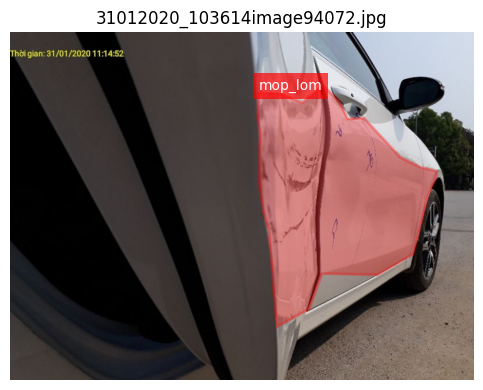

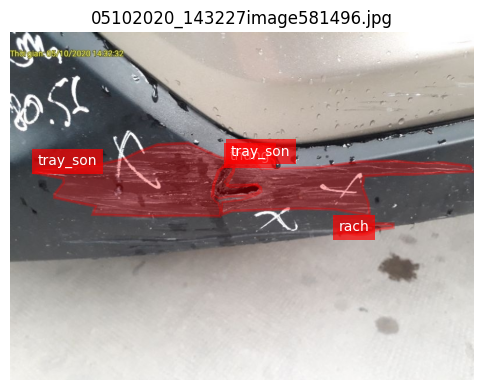

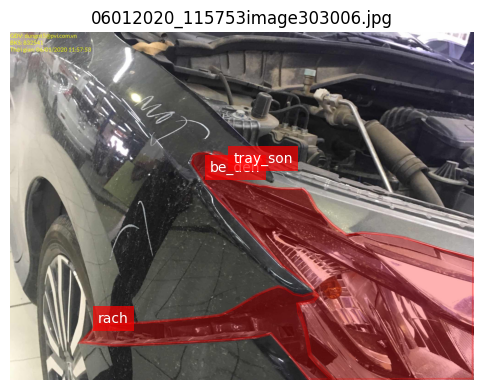

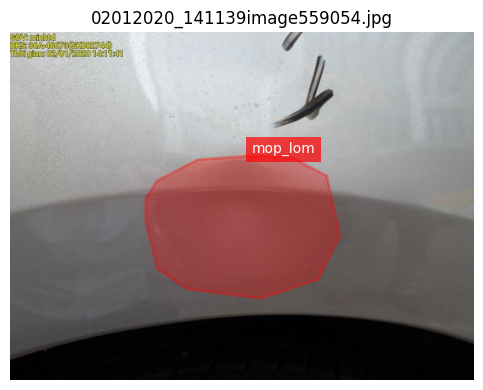

In [17]:
visualize_images_with_VIAannos(
    img_dir=str(VEHIDE_DIR / 'image/image'),
    annotation_file=str(VEHIDE_DIR / '0Train_via_annos.json'),
    num_samples=2,
    seed=42
)

visualize_images_with_VIAannos(
    img_dir=str(VEHIDE_DIR / 'validation/validation'),
    annotation_file=str(VEHIDE_DIR / '0Val_via_annos.json'),
    num_samples=2,
    seed=42
)

## Class Distribution Training and Validation Sets:


 Train Combined JSON
Total image entries:  13621
no_damage entries:  2000
Damage class Instances:
lost parts: 2370
torn: 4546
dent: 4709
paint scratch: 12267
broken glass: 1824
hole: 2006
broken lamp: 2324
no_damage: 2000

 Val Combined JSON
Total image entries:  2824
no_damage entries:  500
Damage class Instances:
torn: 963
paint scratch: 2380
broken glass: 397
lost parts: 448
hole: 417
dent: 972
broken lamp: 458
no_damage: 500


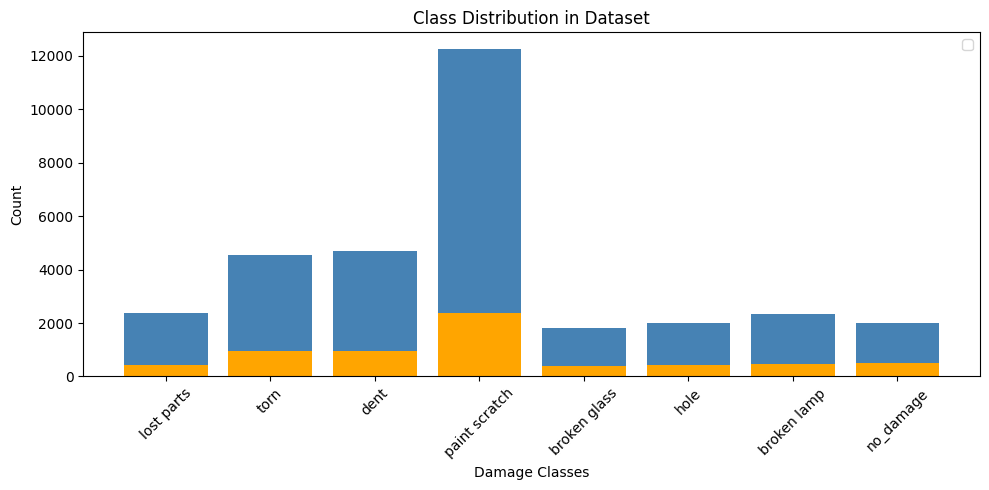

In [18]:
train_class_counts  = check_via_json_stats(str(WORK_DIR / '0Train_combined.json'), label='Train Combined JSON')
val_class_counts  = check_via_json_stats(str(WORK_DIR / '0Val_combined.json'), label='Val Combined JSON')

plt.figure(figsize=(10, 5))
plt.bar(train_class_counts .keys(), train_class_counts .values(), color='steelblue')
plt.bar(val_class_counts .keys(), val_class_counts .values(), color='orange')
plt.xlabel('Damage Classes')
plt.ylabel('Count')
plt.title('Class Distribution in Dataset')
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

## Models:
#### 1.a. Image Classification: ResNet50 Feature Extraction (Fully Frozen)
#### 1.b. Image Classification: ResNet50 Feature Extraction (Partially Fine Tuned)
#### 2. Image Classification: End-to-End CNN Classifier with ResNet50 Backbone
#### 3. Object Detection: Yolo11m for Damage Localization and Classification

## 1.a. Image Classification: ResNet50 Feature Extraction (Fully Frozen)

 - Using Resnet50 as a fixed feature extractor without updating pretrained weights.

In [19]:
#CLASS DEFINITIONS (0-based indexing):
# CLASSES = ['no_damage', 'mat_bo_phan', 'rach', 'mop_lom', 'tray_son', 'thung', 'vo_kinh', 'be_den']
CLASSES = ['no_damage', 'lost parts', 'torn', 'dent', 'paint scratch', 'hole', 'broken glass', 'broken lamp']
CLASS_TO_IDX = {cls_name: idx for idx, cls_name in enumerate(CLASSES)}

#TRANSFORM:
basic_transform = transforms.Compose([
    transforms.Resize((224, 224)),  # suitable for ResNet or VGG
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

# Set paths
train_img_dirs = [str(WORK_DIR / 'yolo_dataset/images/train')]
train_annos_json = str(WORK_DIR / '0Train_combined.json')

# Create dataset and loader
train_dataset = VehicleDamageFeatureDataset(train_img_dirs, train_annos_json, transform=basic_transform)
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2)


# Validation paths
val_img_dirs = [str(WORK_DIR / 'yolo_dataset/images/val')]
val_annos_json = str(WORK_DIR / '0Val_combined.json')

# Validation Dataset & Loader
val_dataset = VehicleDamageFeatureDataset(val_img_dirs, val_annos_json, transform=basic_transform)
val_loader = torch.utils.data.DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2)

- Fixed Feature Extraction using Resnet50::

In [20]:
# Load pretrained ResNet50
resnet = models.resnet50(pretrained=True)

feature_extractor = nn.Sequential(*list(resnet.children())[:-1])  # everything except last linear layer
feature_extractor.eval()
feature_extractor.cuda()

def extract_features_resnet(dataloader, model):
    all_features = []
    all_labels = []

    with torch.no_grad():
        for images, labels in dataloader:
            images = images.cuda()
            features = model(images)  # shape: (batch, 2048, 1, 1)
            features = features.view(features.size(0), -1)  # flatten to (batch, 2048)
            all_features.append(features.cpu().numpy())
            all_labels.append(labels.cpu().numpy())

    features_np = np.vstack(all_features)
    labels_np = np.vstack(all_labels)
    return features_np, labels_np


# Feature extractor using resnet50::
X_train, y_train = extract_features_resnet(train_loader, feature_extractor)
X_val, y_val = extract_features_resnet(val_loader, feature_extractor)

# Feature extractor using HOG - Logic::
# X_train, y_train = extract_features_hog(train_loader)
# X_val, y_val = extract_features_hog(val_loader)


train_df = pd.DataFrame(X_train)
train_labels_df = pd.DataFrame(y_train, columns=[f"label_{i}" for i in range(y_train.shape[1])])
train_full = pd.concat([train_df, train_labels_df], axis=1)
train_full.to_csv(str(WORK_DIR / "train_features.csv"), index=False)

val_df = pd.DataFrame(X_val)
val_labels_df = pd.DataFrame(y_val, columns=[f"label_{i}" for i in range(y_val.shape[1])])
val_full = pd.concat([val_df, val_labels_df], axis=1)
val_full.to_csv(str(WORK_DIR / "val_features.csv"), index=False)

print("Saved train_features and val_features to csv.")

print("Train Feature shapes:", X_train.shape, y_train.shape)
print("Val Feature shapes:", X_val.shape, y_val.shape)

Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 209MB/s]


Saved train_features and val_features to csv.
Train Feature shapes: (13621, 2048) (13621, 8)
Val Feature shapes: (2824, 2048) (2824, 8)


### Apply ML Classifiers on fixed features:
    1. Random Forest
    2. Logistic Regression
    3. MLP Classifier
    4. XGBoost Classifier

In [21]:
# Random Forest
bag = RandomForestClassifier(n_estimators=100, max_samples=0.8, random_state=1)

clf=bag.fit(X_train, y_train)
y_pred=clf.predict(X_val)

confM = multilabel_confusion_matrix(y_val, y_pred)
print(confM)

acc=accuracy_score(y_val, y_pred)
F1=f1_score(y_val, y_pred,average='micro')
precicion = precision_score(y_val, y_pred, average='micro')
recall = recall_score(y_val, y_pred, average='micro', zero_division=0)
print('By hold-out evaluation: acc = ',acc, ',F1 = ',F1, 'precicion =  ' ,precicion , 'recall = ' , recall )
print("\nClassification Report:\n", classification_report(y_val, y_pred, target_names=CLASSES, zero_division=0))

[[[2310   14]
  [  62  438]]

 [[2417    5]
  [ 311   91]]

 [[2157    8]
  [ 623   36]]

 [[2043   31]
  [ 648  102]]

 [[1307  375]
  [ 334  808]]

 [[2506    0]
  [ 317    1]]

 [[2443    1]
  [ 265  115]]

 [[2410    8]
  [ 319   87]]]
By hold-out evaluation: acc =  0.334985835694051 ,F1 =  0.5026209375468025 precicion =   0.7915094339622641 recall =  0.3682247092385341

Classification Report:
                precision    recall  f1-score   support

    no_damage       0.97      0.88      0.92       500
   lost parts       0.95      0.23      0.37       402
         torn       0.82      0.05      0.10       659
         dent       0.77      0.14      0.23       750
paint scratch       0.68      0.71      0.70      1142
         hole       1.00      0.00      0.01       318
 broken glass       0.99      0.30      0.46       380
  broken lamp       0.92      0.21      0.35       406

    micro avg       0.79      0.37      0.50      4557
    macro avg       0.89      0.32      0.39  

In [22]:
# Logistic Regression
clf=OneVsRestClassifier(LogisticRegression(penalty='l2',solver='newton-cg',
                      max_iter=1500))

clf=clf.fit(X_train, y_train)
y_pred=clf.predict(X_val)

confM = multilabel_confusion_matrix(y_val, y_pred)
print(confM)

acc=accuracy_score(y_val, y_pred)
F1=f1_score(y_val, y_pred,average='micro')
precicion = precision_score(y_val, y_pred, average='micro')
recall = recall_score(y_val, y_pred, average='micro', zero_division=0)
print('By hold-out evaluation: acc = ',acc, ',F1 = ',F1, 'precicion =  ' ,precicion , 'recall = ' , recall )
print("\nClassification Report:\n", classification_report(y_val, y_pred, target_names=CLASSES, zero_division=0))

[[[2315    9]
  [   9  491]]

 [[2328   94]
  [ 145  257]]

 [[1955  210]
  [ 325  334]]

 [[1799  275]
  [ 333  417]]

 [[1321  361]
  [ 329  813]]

 [[2410   96]
  [ 204  114]]

 [[2393   51]
  [  92  288]]

 [[2312  106]
  [ 168  238]]]
By hold-out evaluation: acc =  0.4323654390934844 ,F1 =  0.6777637469865687 precicion =   0.7106403466538276 recall =  0.6477946017116524

Classification Report:
                precision    recall  f1-score   support

    no_damage       0.98      0.98      0.98       500
   lost parts       0.73      0.64      0.68       402
         torn       0.61      0.51      0.56       659
         dent       0.60      0.56      0.58       750
paint scratch       0.69      0.71      0.70      1142
         hole       0.54      0.36      0.43       318
 broken glass       0.85      0.76      0.80       380
  broken lamp       0.69      0.59      0.63       406

    micro avg       0.71      0.65      0.68      4557
    macro avg       0.71      0.64      0.67 

In [23]:
# MLP Classifier

mlp = OneVsRestClassifier(MLPClassifier(
    hidden_layer_sizes=(100, 50), activation='relu',solver='adam',alpha=0.0001, batch_size='auto',learning_rate='adaptive',max_iter=200,random_state=1))
clf=mlp.fit(X_train, y_train)
y_pred=clf.predict(X_val)

confM = multilabel_confusion_matrix(y_val, y_pred)
print(confM)

acc=accuracy_score(y_val, y_pred)
F1=f1_score(y_val, y_pred,average='micro')
precicion = precision_score(y_val, y_pred, average='micro')
recall = recall_score(y_val, y_pred, average='micro', zero_division=0)
print('By hold-out evaluation: acc = ',acc, ',F1 = ',F1, 'precicion =  ' ,precicion , 'recall = ' , recall )
print("\nClassification Report:\n", classification_report(y_val, y_pred, target_names=CLASSES, zero_division=0))

[[[2317    7]
  [  11  489]]

 [[2344   78]
  [ 138  264]]

 [[1967  198]
  [ 349  310]]

 [[1580  494]
  [ 198  552]]

 [[1341  341]
  [ 356  786]]

 [[2367  139]
  [ 188  130]]

 [[2380   64]
  [  73  307]]

 [[2283  135]
  [ 140  266]]]
By hold-out evaluation: acc =  0.42103399433427763 ,F1 =  0.6809257431172535 precicion =   0.6807017543859649 recall =  0.6811498793065613

Classification Report:
                precision    recall  f1-score   support

    no_damage       0.99      0.98      0.98       500
   lost parts       0.77      0.66      0.71       402
         torn       0.61      0.47      0.53       659
         dent       0.53      0.74      0.61       750
paint scratch       0.70      0.69      0.69      1142
         hole       0.48      0.41      0.44       318
 broken glass       0.83      0.81      0.82       380
  broken lamp       0.66      0.66      0.66       406

    micro avg       0.68      0.68      0.68      4557
    macro avg       0.70      0.68      0.68

In [25]:
from sklearn.metrics import hamming_loss

# XGBoost Classifier::
xgb = OneVsRestClassifier(XGBClassifier(objective='binary:logistic',
    eval_metric='logloss', scale_pos_weight=1,
    random_state=42, n_jobs=-1, learning_rate=0.1, max_depth=6,
    n_estimators=1000, tree_method='hist', device='cuda' # Enable GPU
))


clf=xgb.fit(X_train, y_train)
y_pred=clf.predict(X_val)

hamming_loss_final_xgb = hamming_loss(y_val, y_pred)
print("Hamming Loss =", hamming_loss_final_xgb)

confM = multilabel_confusion_matrix(y_val, y_pred)
print(confM)

acc=accuracy_score(y_val, y_pred)
F1=f1_score(y_val, y_pred,average='micro')
precicion = precision_score(y_val, y_pred, average='micro')
recall = recall_score(y_val, y_pred, average='micro', zero_division=0)
print('By hold-out evaluation: acc = ',acc, ',F1 = ',F1, 'precicion =  ' ,precicion , 'recall = ' , recall )
print("\nClassification Report:\n", classification_report(y_val, y_pred, target_names=CLASSES, zero_division=0))

# Save your trained MLP model
joblib.dump(xgb, str(WORK_DIR / 'best_xgb_model.joblib'))
print("XGBoost model saved successfully.")

xgb_val_acc = (y_pred == y_val).all(axis=1).mean()
xgb_micro_f1 = f1_score(y_val, y_pred, average='micro')
xgb_report = classification_report(y_val, y_pred, target_names=CLASSES, zero_division=0, output_dict=True)

# print(xgb_report)

add_overall_result(
    model="XGBoost",
    micro_f1=xgb_micro_f1,
    val_acc=xgb_val_acc,
    notes="Fixed Feature Extraction with Resnet50, then XGBoost for classification"
)

print("Overall Results:")
display(overall_results)

add_classwise_results("XGBoost", xgb_report)

print("Classwise Results:")
display(classwise_results)

data = {
    'Model': ["XGBoost with Fixed Feature Extraction"],
    'Hamming Loss': [hamming_loss_final_xgb]
}

final_hamming_loss_df = pd.DataFrame(data)

Hamming Loss = 0.11149964589235127
[[[2307   17]
  [  20  480]]

 [[2386   36]
  [ 161  241]]

 [[2077   88]
  [ 390  269]]

 [[1936  138]
  [ 415  335]]

 [[1349  333]
  [ 274  868]]

 [[2482   24]
  [ 260   58]]

 [[2417   27]
  [ 109  271]]

 [[2383   35]
  [ 192  214]]]
By hold-out evaluation: acc =  0.4656515580736544 ,F1 =  0.6847703666624954 precicion =   0.7967384973791497 recall =  0.6003949967083607

Classification Report:
                precision    recall  f1-score   support

    no_damage       0.97      0.96      0.96       500
   lost parts       0.87      0.60      0.71       402
         torn       0.75      0.41      0.53       659
         dent       0.71      0.45      0.55       750
paint scratch       0.72      0.76      0.74      1142
         hole       0.71      0.18      0.29       318
 broken glass       0.91      0.71      0.80       380
  broken lamp       0.86      0.53      0.65       406

    micro avg       0.80      0.60      0.68      4557
    macro 

,Model,Micro F1,Val Accuracy,mAP@0.5,mAP@0.5:0.95,Notes
0,XGBoost,0.68,0.47,None,None,"Fixed Feature Extraction with Resnet50, then X..."


Classwise Results:


,Model,Class,F1 Score,Precision,Recall
0,XGBoost,no_damage,0.96,0.97,0.96
1,XGBoost,lost parts,0.71,0.87,0.60
2,XGBoost,torn,0.53,0.75,0.41
3,XGBoost,dent,0.55,0.71,0.45
4,XGBoost,paint scratch,0.74,0.72,0.76
5,XGBoost,hole,0.29,0.71,0.18
6,XGBoost,broken glass,0.80,0.91,0.71
7,XGBoost,broken lamp,0.65,0.86,0.53


## 1.b. Image Classification: ResNet50 Feature Extraction (Partial Fine-Tuning)
Partially unfreezing selected layers in ResNet50 to refine features for better classification.

In [26]:
# --- Setup ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
save_path = str(WORK_DIR / "best_improved_resnet_model.pth")

model = ImprovedResNetClassifier(num_classes=len(CLASSES)).to(device)

# --- Class Weights ---
class_counts = np.array([2000, 2370, 4546, 4709, 12267, 1824, 2006, 2324])
total_samples = class_counts.sum()
inv_freq_weights = total_samples / (len(class_counts) * class_counts)
class_weights_tensor = torch.tensor(inv_freq_weights, dtype=torch.float32).to(device)

# --- Loss, Optimizer, Scheduler ---
criterion = nn.BCEWithLogitsLoss(pos_weight=class_weights_tensor)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, 'min', patience=2)

# --- Train Loop ---
EPOCHS = 15
best_micro_f1 = 0.0
results_df = []
hamming_log = pd.DataFrame(columns=["Model", "Epoch", "Hamming Loss"])
classreport_training = pd.DataFrame(columns=['Model','Epoch', 'Class', 'Precision', 'Recall', 'F1', 'Support'])

for epoch in range(EPOCHS):
    model.train()
    train_loss = 0.0
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.float().to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    # --- Validation ---
    model.eval()
    val_loss = 0.0
    all_preds, all_labels = [], []

    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.float().to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            val_loss += loss.item()

            preds = (torch.sigmoid(outputs) >= 0.5).int()
            all_preds.append(preds.cpu())
            all_labels.append(labels.cpu())

    all_preds = torch.cat(all_preds).numpy()
    all_labels = torch.cat(all_labels).numpy()

    train_loss /= len(train_loader)
    val_loss /= len(val_loader)
    micro_f1 = f1_score(all_labels, all_preds, average='micro')
    em_acc = (all_preds == all_labels).all(axis=1).mean()
    hamming_training = hamming_loss(all_labels, all_preds)

    scheduler.step(val_loss)

    # Save best model
    if micro_f1 > best_micro_f1:
        best_micro_f1 = micro_f1
        torch.save(model.state_dict(), save_path)

    # --- Logging ---
    print(f"Epoch {epoch+1}/{EPOCHS} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Micro F1: {micro_f1:.4f} | EM Acc: {em_acc:.4f} | Hamming: {hamming_training:.4f}")

    hamming_log = pd.concat([hamming_log, pd.DataFrame([{
        'Model': "ResNet50 Partial Fine Tuning",
        'Epoch': epoch + 1,
        'Hamming Loss': hamming_training
    }])], ignore_index=True)

    report = classification_report(all_labels, all_preds, target_names=CLASSES, output_dict=True, zero_division=0)

    for class_label, metrics in report.items():
        if class_label in CLASSES:
            classreport_training = pd.concat([classreport_training, pd.DataFrame([{
                'Model': "ImprovedResNet",
                'Epoch': epoch + 1,
                'Class': class_label,
                'Precision': metrics['precision'],
                'Recall': metrics['recall'],
                'F1': metrics['f1-score'],
                'Support': metrics['support']
            }])], ignore_index=True)

    results_df.append({
        'Model': "ImprovedResNet",
        'Epoch': epoch + 1,
        'Train Loss': train_loss,
        'Val Loss': val_loss,
        'Micro F1': micro_f1,
        'Val Acc': em_acc
    })

# --- Save Results ---
pd.DataFrame(results_df).to_csv(EXPORT_DIR / "improvedresnet_results.csv", index=False)
classreport_training.to_csv(EXPORT_DIR / "improvedresnet_classwise.csv", index=False)


# Save dataframes to csv:
classreport_training.to_csv(EXPORT_DIR / "classreport_training.csv", index=False)
# partial_finetuned_results = pd.DataFrame(results_df)
# partial_finetuned_results.to_csv(EXPORT_DIR / "partial_finetuned_results.csv", index=False)
allclass_results = pd.DataFrame(results_df)
allclass_results.to_csv(EXPORT_DIR / "allclass_results.csv", index=False)

print("Partially Fine Tuned Resnet50:")
print(display(allclass_results))

# Add End training results to desired dataframes:
add_overall_result(
    model="Partially Fine Tuned Resnet50",
    micro_f1=micro_f1,
    val_acc=em_acc,
    notes="Unfreeze layer 4 for better image classification."
)

print("Overall Results:")
display(overall_results)

add_classwise_results("Partially Fine Tuned Resnet50", report)

print("Classwise Results:")
display(classwise_results)

final_hamming_loss_df = pd.concat([
    final_hamming_loss_df,
    pd.DataFrame([{
        'Model': "Partially Fine Tuned ResNet50",
        'Hamming Loss': hamming_training
    }])
], ignore_index=True)

hamming_log.to_csv(EXPORT_DIR / "partial_fine_tuned_hamming_loss.csv", index=False)

Epoch 1/15 | Train Loss: 0.4979 | Val Loss: 0.3731 | Micro F1: 0.7123 | EM Acc: 0.4377 | Hamming: 0.1269
Epoch 2/15 | Train Loss: 0.3472 | Val Loss: 0.3137 | Micro F1: 0.7114 | EM Acc: 0.4724 | Hamming: 0.1180
Epoch 3/15 | Train Loss: 0.2396 | Val Loss: 0.2913 | Micro F1: 0.7261 | EM Acc: 0.4986 | Hamming: 0.1096
Epoch 4/15 | Train Loss: 0.1660 | Val Loss: 0.2782 | Micro F1: 0.7417 | EM Acc: 0.5336 | Hamming: 0.0987
Epoch 5/15 | Train Loss: 0.1189 | Val Loss: 0.2732 | Micro F1: 0.7369 | EM Acc: 0.5482 | Hamming: 0.0963
Epoch 6/15 | Train Loss: 0.0885 | Val Loss: 0.2787 | Micro F1: 0.7406 | EM Acc: 0.5322 | Hamming: 0.0979
Epoch 7/15 | Train Loss: 0.0674 | Val Loss: 0.3006 | Micro F1: 0.7466 | EM Acc: 0.5411 | Hamming: 0.0949
Epoch 8/15 | Train Loss: 0.0533 | Val Loss: 0.3263 | Micro F1: 0.7485 | EM Acc: 0.5382 | Hamming: 0.0948
Epoch 9/15 | Train Loss: 0.0379 | Val Loss: 0.2876 | Micro F1: 0.7527 | EM Acc: 0.5574 | Hamming: 0.0911
Epoch 10/15 | Train Loss: 0.0283 | Val Loss: 0.2957 | M

,Model,Epoch,Train Loss,Val Loss,Micro F1,Val Acc
0,ImprovedResNet,1,0.497922,0.373140,0.712307,0.437677
1,ImprovedResNet,2,0.347242,0.313714,0.711409,0.472380
2,ImprovedResNet,3,0.239594,0.291346,0.726147,0.498584
3,ImprovedResNet,4,0.166046,0.278242,0.741685,0.533640
4,ImprovedResNet,5,0.118890,0.273150,0.736880,0.548159
5,ImprovedResNet,6,0.088494,0.278676,0.740584,0.532224
6,ImprovedResNet,7,0.067382,0.300646,0.746600,0.541076
7,ImprovedResNet,8,0.053341,0.326265,0.748502,0.538244
8,ImprovedResNet,9,0.037876,0.287562,0.752673,0.557365
9,ImprovedResNet,10,0.028257,0.295659,0.756951,0.555241


None
Overall Results:


,Model,Micro F1,Val Accuracy,mAP@0.5,mAP@0.5:0.95,Notes
0,XGBoost,0.68,0.47,None,None,"Fixed Feature Extraction with Resnet50, then X..."
1,Partially Fine Tuned Resnet50,0.76,0.56,None,None,Unfreeze layer 4 for better image classification.


Classwise Results:


,Model,Class,F1 Score,Precision,Recall
0,XGBoost,no_damage,0.96,0.97,0.96
1,XGBoost,lost parts,0.71,0.87,0.60
2,XGBoost,torn,0.53,0.75,0.41
3,XGBoost,dent,0.55,0.71,0.45
4,XGBoost,paint scratch,0.74,0.72,0.76
5,XGBoost,hole,0.29,0.71,0.18
6,XGBoost,broken glass,0.80,0.91,0.71
7,XGBoost,broken lamp,0.65,0.86,0.53
8,Partially Fine Tuned Resnet50,no_damage,0.99,0.99,0.99
9,Partially Fine Tuned Resnet50,lost parts,0.78,0.79,0.77


In [27]:
# # Add End training results to desired dataframes:
# add_overall_result(
#     model="Partially Fine Tuned Resnet50",
#     micro_f1=micro_f1,
#     val_acc=em_acc,
#     notes="Unfreeze layer 4 for better image classification."
# )

# print("Overall Results:")
# display(overall_results)

# add_classwise_results("Partially Fine Tuned Resnet50", report)

# print("Classwise Results:")
# display(classwise_results)

# final_hamming_loss_df = pd.concat([
#     final_hamming_loss_df,
#     pd.DataFrame([{
#         'Model': "Partially Fine Tuned ResNet50",
#         'Hamming Loss': hamming_training
#     }])
# ], ignore_index=True)

# hamming_log.to_csv(EXPORT_DIR / "partial_fine_tuned_hamming_loss.csv", index=False)

In [28]:
display(hamming_log)

,Model,Epoch,Hamming Loss
0,ResNet50 Partial Fine Tuning,1,0.126859
1,ResNet50 Partial Fine Tuning,2,0.118006
2,ResNet50 Partial Fine Tuning,3,0.109641
3,ResNet50 Partial Fine Tuning,4,0.098663
4,ResNet50 Partial Fine Tuning,5,0.096317
5,ResNet50 Partial Fine Tuning,6,0.097867
6,ResNet50 Partial Fine Tuning,7,0.094857
7,ResNet50 Partial Fine Tuning,8,0.094768
8,ResNet50 Partial Fine Tuning,9,0.091138
9,ResNet50 Partial Fine Tuning,10,0.089766


In [29]:
final_hamming_loss_df = pd.concat([
    final_hamming_loss_df,
    pd.DataFrame([{
        'Model': "Partially Fine Tuned ResNet50",
        'Hamming Loss': hamming_training
    }])
], ignore_index=True)

display(final_hamming_loss_df)

,Model,Hamming Loss
0,XGBoost with Fixed Feature Extraction,0.111500
1,Partially Fine Tuned ResNet50,0.088704
2,Partially Fine Tuned ResNet50,0.088704


In [30]:
# results_df = []
# classreport_training = pd.DataFrame(columns=['Model','Epoch', 'Class', 'Precision', 'Recall', 'F1', 'Support'])
# best_micro_f1 = 0.0
# save_path = str(WORK_DIR / 'best_partial_tuned_model.pth')

# model = ResNetWithClassifier(num_classes=len(CLASSES)).to(device)

# # LOSS & OPTIMIZER:
# class_counts = np.array([2000, 2370, 4546, 4709, 12267, 1824, 2006, 2324])
# total_samples = sum(class_counts)
# num_classes = len(class_counts)
# inv_freq_weights = total_samples / (num_classes * class_counts)
# class_weights_tensor = torch.tensor(inv_freq_weights, dtype=torch.float32).to(device)

# criterion = nn.BCEWithLogitsLoss(pos_weight=class_weights_tensor)
# optimizer = optim.Adam(model.parameters(), lr=1e-4)

# # Train model:
# EPOCHS = 15
# for epoch in range(EPOCHS):
#     model.train()
#     train_loss = 0.0
#     for inputs, labels in train_loader:
#         inputs = inputs.to(device)
#         labels = labels.float().to(device)

#         optimizer.zero_grad()
#         outputs = model(inputs)
#         loss = criterion(outputs, labels)
#         loss.backward()
#         optimizer.step()

#         train_loss += loss.item()

#     # Model Evaluation:
#     model.eval()
#     val_loss = 0.0
#     all_preds, all_labels = [], []
#     with torch.no_grad():
#         for inputs, labels in val_loader:
#             inputs = inputs.to(device)
#             labels = labels.float().to(device)

#             outputs = model(inputs)
#             loss = criterion(outputs, labels)
#             val_loss += loss.item()

#             preds = (torch.sigmoid(outputs) >= 0.5).int()
#             all_preds.append(preds.cpu())
#             all_labels.append(labels.cpu())

#     all_preds = torch.cat(all_preds).numpy()
#     all_labels = torch.cat(all_labels).numpy()

#     micro_f1 = f1_score(all_labels, all_preds, average='micro')
#     exact_match = (all_preds == all_labels).all(axis=1).mean()
#     report = classification_report(all_labels, all_preds, target_names=CLASSES, zero_division=0, output_dict = True)

#     if micro_f1 > best_micro_f1:
#         best_micro_f1 = micro_f1
#         torch.save(model.state_dict(), save_path)

#     # Write all results desired dataframes:
#     for class_label, metrics in report.items():
#         if class_label not in ['micro avg', 'macro avg', 'weighted avg', 'samples avg']:
#             row = {
#                 'Model': "Resnet50 Partial Fine Tuning",
#                 'Epoch': epoch+1,
#                 'Class': class_label,
#                 'Precision': metrics['precision'],
#                 'Recall': metrics['recall'],
#                 'F1': metrics['f1-score'],
#                 'Support': metrics['support']
#             }
#             classreport_training = pd.concat([classreport_training, pd.DataFrame([row])], ignore_index=True)

#     results_df.append({
#         "Model": "Partially Fine Tuned Resnet50",
#         "Epoch": epoch + 1,
#         "Train Loss": train_loss / len(train_loader),
#         "Val Loss": val_loss / len(val_loader),
#         "Micro F1": micro_f1,
#         "Val Acc": exact_match
#     })

#     print(f"Epoch {epoch+1}/{EPOCHS} | Train Loss: {train_loss / len(train_loader):.4f} | "
#           f"Val Loss: {val_loss / len(val_loader):.4f} | Micro F1: {micro_f1:.4f} | EM Acc: {exact_match:.4f}")
#     # print(classification_report(all_labels, all_preds, target_names=CLASSES, zero_division=0))


# # Save dataframes to csv:
# classreport_training.to_csv(EXPORT_DIR / "classreport_training.csv", index=False)
# # partial_finetuned_results = pd.DataFrame(results_df)
# # partial_finetuned_results.to_csv(EXPORT_DIR / "partial_finetuned_results.csv", index=False)
# allclass_results = pd.DataFrame(results_df)
# allclass_results.to_csv(EXPORT_DIR / "allclass_results.csv", index=False)

# print("Partially Fine Tuned Resnet50:")
# print(display(allclass_results))

# # Add End training results to desired dataframes:
# add_overall_result(
#     model="Partially Fine Tuned Resnet50",
#     micro_f1=micro_f1,
#     val_acc=exact_match,
#     notes="Unfreeze layer 4 for better image classification."
# )

# print("Overall Results:")
# display(overall_results)

# add_classwise_results("Partially Fine Tuned Resnet50", report)

# print("Classwise Results:")
# display(classwise_results)

## 2. Image Classification with End to End CNN using Resnet50 backbone::

In [31]:
# Define classes and model parameters:
# CLASSES = ['no_damage', 'mat_bo_phan', 'rach', 'mop_lom', 'tray_son', 'thung', 'vo_kinh', 'be_den']
CLASSES = ['no_damage', 'lost parts', 'torn', 'dent', 'paint scratch', 'hole', 'broken glass', 'broken lamp']
CLASS_TO_IDX = {cls_name: i for i, cls_name in enumerate(CLASSES)}
BATCH_SIZE = 32
LR = 0.0001
EPOCHS = 10
best_f1_score = 0

# TRANSFORMS:
transform = transforms.Compose([
    transforms.Resize((512, 512)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(0.2, 0.2, 0.2),
    transforms.ToTensor(),
    transforms.RandomAdjustSharpness(1.5, p=0.5),
    transforms.RandomAutocontrast(p=0.3),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])

# Load train and val data:
train_data = VehicleDamageDataset(
    image_dirs=[
        str(WORK_DIR / 'yolo_dataset/images/train')],
    annotations_file=str(WORK_DIR / '0Train_combined.json'),
    transform=transform
)

val_data = VehicleDamageDataset(
    image_dirs=[str(WORK_DIR / 'yolo_dataset/images/val')],
    annotations_file=str(WORK_DIR / '0Val_combined.json'),
    transform=transform
)

train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True, num_workers=4)
val_loader = DataLoader(val_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=4)

In [32]:
# Check if data loaded successfully:
check_dataloader(train_loader, "Train Loader")
check_dataloader(val_loader, "Validation Loader")

Train Loader  loaded successfully.
   Number of batches:  426
   Image batch shape:  torch.Size([32, 3, 512, 512])
   Label batch shape:  torch.Size([32, 8])
Validation Loader  loaded successfully.
   Number of batches:  89
   Image batch shape:  torch.Size([32, 3, 512, 512])
   Label batch shape:  torch.Size([32, 8])


In [33]:
# Initialize Resnet50 backbone with 3 hidden layers:

class DamageNet(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.base = models.resnet50(weights='DEFAULT')
        in_features = self.base.fc.in_features
        self.base.fc = nn.Sequential(
            nn.Linear(in_features, 1024),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(1024, 512),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        return self.base(x)

# results_df = []
model = DamageNet(len(CLASSES)).to(device)

hamming_log_endtoend = pd.DataFrame(columns=["Model", "Epoch", "Hamming Loss"])
# LOSS & OPTIMIZER:
criterion = FocalLoss(gamma=2.0)
optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, 'min', patience=2)

# Model training:
for epoch in range(EPOCHS):
    epoch_start_time = time.time()
    print("Epoch ", epoch+1, "started.")
    model.train()
    train_loss = 0.0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()

    model.eval()
    val_loss = 0.0
    correct = 0
    all_preds, all_labels = [], []

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            val_loss += criterion(outputs, labels).item()

            preds = (torch.sigmoid(outputs) > 0.5).int()
            all_preds.append(preds.cpu().numpy())
            all_labels.append(labels.cpu().numpy())
            correct += (preds == labels.bool()).all(dim=1).sum().item()

    all_preds = np.vstack(all_preds)
    all_labels = np.vstack(all_labels)

    train_loss /= len(train_loader)
    val_loss /= len(val_loader)
    val_acc = correct / len(val_data)

    micro_f1 = f1_score(all_labels, all_preds, average='micro')
    classreport = classification_report(all_labels, all_preds, output_dict=True)
    hamming_training = hamming_loss(all_labels, all_preds)

    scheduler.step(val_loss)
    hamming_log_endtoend = pd.concat([hamming_log_endtoend, pd.DataFrame([{
        'Model': "End to End CNN with ResNet50 backbone",
        'Epoch': epoch + 1,
        'Hamming Loss': hamming_training
    }])], ignore_index=True)

    # Save the model based on highest micro F1:
    if micro_f1 > best_f1_score:
        best_f1_score = micro_f1
        torch.save({
            'model_state_dict': model.state_dict(),
            'class_to_idx': CLASS_TO_IDX,
            'optimizer_state_dict': optimizer.state_dict(),
            'micro_f1_score': micro_f1,
        }, str(WORK_DIR / 'best_damagenet_model.pth'))

    epoch_end_time = time.time()
    epoch_duration = epoch_end_time - epoch_start_time

    # Write Epoch results to desired dataframes:
    for class_label, metrics in classreport.items():
        if class_label not in ['micro avg', 'macro avg', 'weighted avg', 'samples avg']:
            row = {
                'Model': "End to End CNN Classifier with Resnet50 backbone",
                'Epoch': epoch+1,
                'Class': CLASSES[int(class_label)],
                'Precision': metrics['precision'],
                'Recall': metrics['recall'],
                'F1': metrics['f1-score'],
                'Support': metrics['support']
            }
            classreport_training = pd.concat([classreport_training, pd.DataFrame([row])], ignore_index=True)

    results_df.append({
        "Model": "End to End CNN Classifier with Resnet50 backbone",
        "Epoch": epoch + 1,
        "Train Loss": train_loss / len(train_loader),
        "Val Loss": val_loss / len(val_loader),
        "Micro F1": micro_f1,
        "Val Acc": val_acc
    })

    # GPU memory usage (if using CUDA)
    if torch.cuda.is_available():
        allocated_memory = torch.cuda.memory_allocated(device) / (1024**3)  # Convert to GB
        cached_memory = torch.cuda.memory_cached(device) / (1024**3)  # Convert to GB
        print(f"GPU Memory - Allocated: {allocated_memory:.2f} GB, Cached: {cached_memory:.2f} GB")

    print(f"Epoch {epoch+1}/{EPOCHS} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f} | Micro F1: {micro_f1:.4f} | Hamming: {hamming_training:.4f}")
    print(f"Epoch {epoch+1} Duration: {epoch_duration:.2f} seconds")  # Execution time per epoch
    # print("\n--- Classification Report ---")
    # print(classification_report(all_labels, all_preds, target_names=CLASSES, zero_division=0))

# Write End training results to desired dataframes:
classreport_training.to_csv(EXPORT_DIR / "classreport_training.csv", index=False)
print("All class results: ", results_df)
allclass_results = pd.DataFrame(results_df)
allclass_results.to_csv(EXPORT_DIR / "endtoend.csv", index=False)


print("Added End to End CNN Classifier with Resnet50 backbone:")
print(display(allclass_results[16:]))

final_hamming_loss_df = pd.concat([
    final_hamming_loss_df,
    pd.DataFrame([{
        'Model': "End to End CNN Classifier with Resnet50 backbone",
        'Hamming Loss': hamming_training
    }])
], ignore_index=True)

hamming_log_endtoend.to_csv(EXPORT_DIR / "endtoendcnn_hamming_loss.csv", index=False)

hamming_log = pd.concat([hamming_log, hamming_log_endtoend], ignore_index=True)

hamming_log.to_csv(EXPORT_DIR / "hamming_loss.csv", index=False)
display(hamming_log)
display(final_hamming_loss_df)
# resnet50_results = pd.DataFrame(results_df)
# resnet50_results.to_csv(EXPORT_DIR / "resnet50_results.csv", index=False)
# print("Saved epoch-wise results to resnet50_results.csv")
# print("Training complete!")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 241MB/s]


Epoch  1 started.
GPU Memory - Allocated: 0.53 GB, Cached: 14.22 GB
Epoch 1/10 | Train Loss: 0.0855 | Val Loss: 0.0626 | Val Acc: 0.5067 | Micro F1: 0.6951 | Hamming: 0.1082
Epoch 1 Duration: 772.01 seconds
Epoch  2 started.
GPU Memory - Allocated: 0.53 GB, Cached: 14.22 GB
Epoch 2/10 | Train Loss: 0.0612 | Val Loss: 0.0558 | Val Acc: 0.5552 | Micro F1: 0.7566 | Hamming: 0.0896
Epoch 2 Duration: 774.43 seconds
Epoch  3 started.
GPU Memory - Allocated: 0.53 GB, Cached: 14.22 GB
Epoch 3/10 | Train Loss: 0.0514 | Val Loss: 0.0535 | Val Acc: 0.5758 | Micro F1: 0.7793 | Hamming: 0.0832
Epoch 3 Duration: 773.68 seconds
Epoch  4 started.
GPU Memory - Allocated: 0.53 GB, Cached: 14.22 GB
Epoch 4/10 | Train Loss: 0.0440 | Val Loss: 0.0520 | Val Acc: 0.5768 | Micro F1: 0.7898 | Hamming: 0.0819
Epoch 4 Duration: 779.89 seconds
Epoch  5 started.
GPU Memory - Allocated: 0.53 GB, Cached: 14.22 GB
Epoch 5/10 | Train Loss: 0.0373 | Val Loss: 0.0549 | Val Acc: 0.5676 | Micro F1: 0.7892 | Hamming: 0.085

,Model,Epoch,Train Loss,Val Loss,Micro F1,Val Acc
16,End to End CNN Classifier with Resnet50 backbone,2,0.000144,0.000627,0.756640,0.555241
17,End to End CNN Classifier with Resnet50 backbone,3,0.000121,0.000601,0.779331,0.575779
18,End to End CNN Classifier with Resnet50 backbone,4,0.000103,0.000584,0.789820,0.576841
19,End to End CNN Classifier with Resnet50 backbone,5,0.000087,0.000617,0.789227,0.567635
20,End to End CNN Classifier with Resnet50 backbone,6,0.000074,0.000653,0.793308,0.584986
21,End to End CNN Classifier with Resnet50 backbone,7,0.000063,0.000679,0.797281,0.566218
22,End to End CNN Classifier with Resnet50 backbone,8,0.000042,0.000735,0.812180,0.606232
23,End to End CNN Classifier with Resnet50 backbone,9,0.000033,0.000800,0.811549,0.603045
24,End to End CNN Classifier with Resnet50 backbone,10,0.000029,0.000822,0.815210,0.609419


None


,Model,Epoch,Hamming Loss
0,ResNet50 Partial Fine Tuning,1,0.126859
1,ResNet50 Partial Fine Tuning,2,0.118006
2,ResNet50 Partial Fine Tuning,3,0.109641
3,ResNet50 Partial Fine Tuning,4,0.098663
4,ResNet50 Partial Fine Tuning,5,0.096317
5,ResNet50 Partial Fine Tuning,6,0.097867
6,ResNet50 Partial Fine Tuning,7,0.094857
7,ResNet50 Partial Fine Tuning,8,0.094768
8,ResNet50 Partial Fine Tuning,9,0.091138
9,ResNet50 Partial Fine Tuning,10,0.089766


,Model,Hamming Loss
0,XGBoost with Fixed Feature Extraction,0.111500
1,Partially Fine Tuned ResNet50,0.088704
2,Partially Fine Tuned ResNet50,0.088704
3,End to End CNN Classifier with Resnet50 backbone,0.073566


In [34]:
final_hamming_loss_df.loc[2, 'Model'] = "End to End CNN Classifier with Resnet50 backbone"
display(final_hamming_loss_df)

,Model,Hamming Loss
0,XGBoost with Fixed Feature Extraction,0.111500
1,Partially Fine Tuned ResNet50,0.088704
2,End to End CNN Classifier with Resnet50 backbone,0.088704
3,End to End CNN Classifier with Resnet50 backbone,0.073566


#### Threshold tuning:

In [35]:
# Load the best model for threshold tuning:
checkpoint = torch.load(str(WORK_DIR / 'best_damagenet_model.pth'))
model.load_state_dict(checkpoint['model_state_dict'])
model.to(device)
model.eval()

# Calculate probabilities and predict labels on validation set:
all_probs = []
all_labels = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        outputs = model(images)
        probs = torch.sigmoid(outputs).cpu().numpy()
        all_probs.append(probs)
        all_labels.append(labels.cpu().numpy())

all_probs = np.vstack(all_probs)
all_labels = np.vstack(all_labels)

# Tune thresholds:
def tune_thresholds_dmgnet(all_probs, all_labels, thresholds=np.arange(0.1, 0.91, 0.01)):
    best_thresholds = []
    for class_idx in range(all_probs.shape[1]):
        best_f1 = 0
        best_t = 0.5
        for t in thresholds:
            preds = (all_probs[:, class_idx] >= t).astype(int)
            f1 = f1_score(all_labels[:, class_idx], preds, zero_division=0)
            if f1 > best_f1:
                best_f1 = f1
                best_t = t
        best_thresholds.append(best_t)
    return best_thresholds

best_thresholds_damagenet = tune_thresholds_dmgnet(all_probs, all_labels)
print("Best per-class thresholds:", best_thresholds_damagenet)

# === Apply best thresholds and evaluate ===
final_preds = (all_probs >= best_thresholds_damagenet).astype(int)
print("\nFinal Evaluation with Tuned Thresholds:")
print("Hamming Loss = ", hamming_loss(all_labels, final_preds))
print(classification_report(all_labels, final_preds, target_names=CLASSES, zero_division=0))

Best per-class thresholds: [np.float64(0.45999999999999985), np.float64(0.45999999999999985), np.float64(0.3699999999999999), np.float64(0.4199999999999998), np.float64(0.4299999999999998), np.float64(0.4999999999999998), np.float64(0.3999999999999998), np.float64(0.32999999999999985)]

Final Evaluation with Tuned Thresholds:
Hamming Loss =  0.07617740793201133
               precision    recall  f1-score   support

    no_damage       1.00      1.00      1.00       500
   lost parts       0.84      0.81      0.83       402
         torn       0.68      0.80      0.74       659
         dent       0.73      0.79      0.76       750
paint scratch       0.76      0.87      0.81      1142
         hole       0.71      0.73      0.72       318
 broken glass       0.94      0.92      0.93       380
  broken lamp       0.80      0.87      0.84       406

    micro avg       0.79      0.85      0.82      4557
    macro avg       0.81      0.85      0.83      4557
 weighted avg       0.79     

##### Calculate model performance after threshold tuning and write into dataframes:

In [36]:
micro_f1 = f1_score(all_labels, final_preds, average='micro')
val_acc = (final_preds == all_labels).all(axis=1).mean()
report = classification_report(all_labels, final_preds, target_names=CLASSES, zero_division=0, output_dict=True)

add_overall_result(
    model="End to End CNN Classifier with Resnet50 backbone",
    micro_f1=micro_f1,
    val_acc=val_acc,
    notes="End to End CNN Classifier with Resnet50 backbone"
)

print("Overall Results:")
display(overall_results)


add_classwise_results("End to End CNN Classifier with Resnet50 backbone", report)

print("Classwise Results:")
display(classwise_results)

Overall Results:


,Model,Micro F1,Val Accuracy,mAP@0.5,mAP@0.5:0.95,Notes
0,XGBoost,0.68,0.47,None,None,"Fixed Feature Extraction with Resnet50, then X..."
1,Partially Fine Tuned Resnet50,0.76,0.56,None,None,Unfreeze layer 4 for better image classification.
2,End to End CNN Classifier with Resnet50 backbone,0.82,0.59,None,None,End to End CNN Classifier with Resnet50 backbone


Classwise Results:


,Model,Class,F1 Score,Precision,Recall
0,XGBoost,no_damage,0.96,0.97,0.96
1,XGBoost,lost parts,0.71,0.87,0.60
2,XGBoost,torn,0.53,0.75,0.41
3,XGBoost,dent,0.55,0.71,0.45
4,XGBoost,paint scratch,0.74,0.72,0.76
5,XGBoost,hole,0.29,0.71,0.18
6,XGBoost,broken glass,0.80,0.91,0.71
7,XGBoost,broken lamp,0.65,0.86,0.53
8,Partially Fine Tuned Resnet50,no_damage,0.99,0.99,0.99
9,Partially Fine Tuned Resnet50,lost parts,0.78,0.79,0.77


In [37]:
# micro_f1 = f1_score(all_labels, final_preds, average='micro')
# val_acc = (final_preds == all_labels).all(axis=1).mean()
# report = classification_report(all_labels, final_preds, target_names=CLASSES, output_dict=True, zero_division=0)

# # Add to overall metrics
# add_overall_result(
#     model="DamageNet_ResNet50",
#     micro_f1=micro_f1,
#     val_acc=val_acc,
#     notes="CNN with ResNet50 backbone and sigmoid thresholds per class"
# )

# # Add to class-wise metrics
# add_classwise_results("DamageNet_ResNet50", report)

## 3. Object Detection - YOLO11m::

In [38]:
import torch
print(torch.cuda.device_count())
print([torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())])

2
['Tesla T4', 'Tesla T4']


In [1]:
import gc
import torch

# حذف أي موديلات قديمة من الرام
try:
    del model
    del train_loader
    del val_loader
except:
    pass

gc.collect()
torch.cuda.empty_cache()

print("تم تفريغ ذاكرة كارت الشاشة بنجاح! ✅")


تم تفريغ ذاكرة كارت الشاشة بنجاح! ✅


In [23]:
# 1. تثبيت ultralytics
!pip install ultralytics -q

# 2. استدعاء المكتبات وتعريف المسار
from pathlib import Path
from ultralytics import YOLO

WORK_DIR = Path("/kaggle/working")

# 3. تحميل وتدريب الموديل
model = YOLO('yolo11m.pt')

results = model.train(
    data=str(WORK_DIR / 'dataset.yaml'), 
    epochs=50, 
    imgsz=640, 
    batch=16,
    optimizer='SGD', 
    lr0=0.001, 
    cos_lr=True, 
    patience=10, 
    overlap_mask=True,
    augment=True, 
    copy_paste=0.1, 
    retina_masks=True, 
    amp=True, 
    pretrained=True,
    exist_ok=True,
    project=str(WORK_DIR / 'yolo11_results'), 
    name='best_yolo11_model',
    save_period=10,
    scale=0.5, 
    perspective=0.001, 
    shear=0.01,
    device=0,
    workers=2
)

# 4. حفظ أفضل موديل وتصديره
best_model_path = str(WORK_DIR / 'best_yolo11_model.pt')
model.export(format='onnx')
!cp {results.save_dir}/weights/best.pt {best_model_path}
print(f"✅ Best model saved successfully to: {best_model_path}")


Ultralytics 8.4.178 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=True, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.1, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/dataset.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11m.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=best_yolo11_model, nbs=64, nms=None, opset=None, optimize=Fals

In [24]:
import os
partial = "/kaggle/working/working_files.zip"
if partial.exists():
    os.remove(partial)
    print("Deleted partial zip")

AttributeError: 'str' object has no attribute 'exists'

In [ ]:
import os
from IPython.display import FileLink

# Zip the contents of /kaggle/working
!zip -r working_files.zip /kaggle/working/*

# Generate a download link
FileLink('working_files.zip')

### Adding Fine-tuning:

# Label Cleaning + Fine-tuning for Vehicle Damage Detection

This notebook contains the label-cleaning and fine-tuning steps to run immediately after the dataset processing stage in the main training notebook.

> The original code assumes a Google Colab-style directory layout under `/content/kaggle/working/...`. Update the paths if you are running locally.

In [26]:
import glob
import os
import shutil
from itertools import combinations

from ultralytics import YOLO

best_pt_path = best_model_path

## 1) Label cleaning setup

These utilities remove degenerate `no_damage` boxes and near-duplicate boxes before fine-tuning.

In [27]:
LABELS_DIR = str(WORK_DIR / 'yolo_dataset/labels/train')
IOU_DEDUP_THRESHOLD = 0.85
DEGENERATE_AREA_THRESHOLD = 0.90
NO_DAMAGE_CLASS_ID = 0

def box_iou_xywh(b1, b2):
    """IoU between two YOLO-format boxes (cx, cy, w, h), normalized 0-1."""
    def to_xyxy(b):
        cx, cy, w, h = b
        return cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2

    x1a, y1a, x2a, y2a = to_xyxy(b1)
    x1b, y1b, x2b, y2b = to_xyxy(b2)

    inter_x1, inter_y1 = max(x1a, x1b), max(y1a, y1b)
    inter_x2, inter_y2 = min(x2a, x2b), min(y2a, y2b)
    inter_w, inter_h = max(0, inter_x2 - inter_x1), max(0, inter_y2 - inter_y1)
    inter_area = inter_w * inter_h

    area_a = (x2a - x1a) * (y2a - y1a)
    area_b = (x2b - x1b) * (y2b - y1b)
    union = area_a + area_b - inter_area
    return inter_area / union if union > 0 else 0.0


def clean_label_file(path, log):
    """Clean a single YOLO label file: remove duplicates and degenerate boxes."""
    with open(path) as f:
        lines = [l.strip() for l in f if l.strip()]

    boxes = []
    for line in lines:
        parts = line.split()
        cls_id = int(parts[0])
        cx, cy, w, h = map(float, parts[1:5])
        boxes.append((cls_id, cx, cy, w, h))

    kept = list(boxes)

    # Remove degenerate no_damage boxes that cover >90% of image AND co-exist with real damage
    has_other_damage = any(b[0] != NO_DAMAGE_CLASS_ID for b in kept)
    if has_other_damage:
        new_kept = []
        for b in kept:
            cls_id, cx, cy, w, h = b
            if cls_id == NO_DAMAGE_CLASS_ID and (w * h) > DEGENERATE_AREA_THRESHOLD:
                log['degenerate_removed'] += 1
                continue
            new_kept.append(b)
        kept = new_kept

    # Remove near-duplicate boxes of the same class
    to_drop = set()
    for i, j in combinations(range(len(kept)), 2):
        if i in to_drop or j in to_drop:
            continue
        bi, bj = kept[i], kept[j]
        if bi[0] != bj[0]:
            continue
        iou = box_iou_xywh(bi[1:], bj[1:])
        if iou >= IOU_DEDUP_THRESHOLD:
            to_drop.add(j)
            log['duplicates_removed'] += 1

    kept = [b for k, b in enumerate(kept) if k not in to_drop]

    with open(path, 'w') as f:
        for cls_id, cx, cy, w, h in kept:
            f.write(f"{cls_id} {cx:.6f} {cy:.6f} {w:.6f} {h:.6f}\n")

    return len(boxes), len(kept)


def clean_dataset(labels_dir):
    """Clean all label files in the training set."""
    log = {'degenerate_removed': 0, 'duplicates_removed': 0, 'files_changed': 0}
    label_files = sorted(glob.glob(os.path.join(labels_dir, "*.txt")))
    print(f"Found {len(label_files)} label files.")

    for i, path in enumerate(label_files):
        before, after = clean_label_file(path, log)
        if after != before:
            log['files_changed'] += 1
        if (i + 1) % max(1, len(label_files) // 10) == 0:
            print(f"  Processed {i + 1}/{len(label_files)}...")

    return log

print("✓ Label cleaning functions defined")

✓ Label cleaning functions defined


## 2) Backup and clean labels

In [28]:
backup_dir = LABELS_DIR + "_backup"
if not os.path.exists(backup_dir):
    print(f"Creating backup of original labels...")
    shutil.copytree(LABELS_DIR, backup_dir)
    print(f"✓ Backup saved to {backup_dir}")
else:
    print(f"✓ Backup already exists at {backup_dir}")

print("\nCleaning labels...")
log = clean_dataset(LABELS_DIR)
print(f"\n✓ Label cleaning complete:")
print(f"  Files with changes: {log['files_changed']}")
print(f"  Degenerate no_damage boxes removed: {log['degenerate_removed']}")
print(f"  Duplicate boxes removed: {log['duplicates_removed']}")
print(f"  Total boxes removed: {log['degenerate_removed'] + log['duplicates_removed']}")

Creating backup of original labels...
✓ Backup saved to /kaggle/working/yolo_dataset/labels/train_backup

Cleaning labels...
Found 13621 label files.
  Processed 1362/13621...
  Processed 2724/13621...
  Processed 4086/13621...
  Processed 5448/13621...
  Processed 6810/13621...
  Processed 8172/13621...
  Processed 9534/13621...
  Processed 10896/13621...
  Processed 12258/13621...
  Processed 13620/13621...

✓ Label cleaning complete:
  Files with changes: 0
  Degenerate no_damage boxes removed: 0
  Duplicate boxes removed: 0
  Total boxes removed: 0


## 3) Fine-tune from existing best.pt

This step fine-tunes the current model using the cleaned labels.

In [29]:
best_pt_path = str(WORK_DIR / 'yolo11_results/best_yolo11_model/weights/best.pt')

if not os.path.exists(best_pt_path):
    print(f"❌ ERROR: best.pt not found at {best_pt_path}")
    print(f"Make sure you've run the original YOLO training cell first.")
    raise FileNotFoundError(f"best.pt not found")
else:
    size_mb = os.path.getsize(best_pt_path) / 1e6
    print(f"✓ Found best.pt ({size_mb:.1f} MB)")

print("\nLoading model for fine-tuning...")
model = YOLO(best_pt_path)

print("\nStarting fine-tuning (20 epochs with AdamW, low LR)...\n")
results = model.train(
    data=str(WORK_DIR / 'dataset.yaml'),
    epochs=20,
    imgsz=640,
    batch=32,
    optimizer="AdamW",
    lr0=0.0002,
    cos_lr=True,
    patience=15,
    close_mosaic=0,
    augment=True,
    amp=True,
    pretrained=False,
    exist_ok=True,
    project=str(WORK_DIR / 'yolo11_finetune_v2'),
    name='finetune_v2',
    save_period=5,
    scale=0.5,
    perspective=0.001,
    shear=0.01,
    device=[0,1],
    workers=4,
)

print(f"\n✓ Fine-tuning complete!")
print(f"  Best weights saved to: {results.save_dir}/weights/best.pt")

✓ Found best.pt (40.5 MB)

Loading model for fine-tuning...

Starting fine-tuning (20 epochs with AdamW, low LR)...

Ultralytics 8.4.178 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
                                                        CUDA:1 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=True, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/dataset.yaml, degrees=0.0, deterministic=True, device=0,1, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None,

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(



      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       2/20      7.99G      2.303      3.374      2.674         51        640: 100% ━━━━━━━━━━━━ 426/426 2.4it/s 2:580.4ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 45/45 2.7it/s 16.9s0.3s
                   all       2824       6535      0.294      0.163       0.14     0.0874

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/20      8.06G      2.089      3.138      2.449         39        640: 100% ━━━━━━━━━━━━ 426/426 2.4it/s 2:560.4ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 45/45 2.7it/s 16.8s0.4s
                   all       2824       6535      0.383      0.168     0.0976     0.0708

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/20      8.07G      1.964      2.978      2.322         69        6

AttributeError: 'dict' object has no attribute 'save_dir'

## 4) Save fine-tuned model

In [31]:
import shutil

source_pt = str(WORK_DIR / 'yolo11_finetune_v2/finetune_v2/weights/best.pt')
best_finetuned_path = str(WORK_DIR / 'best_finetuned_v2.pt')

shutil.copy(source_pt, best_finetuned_path)
print(f"✓ Fine-tuned model saved to: {best_finetuned_path}")


✓ Fine-tuned model saved to: /kaggle/working/best_finetuned_v2.pt


## 5) Quick validation (optional)

In [32]:
val_images = sorted(glob.glob(str(WORK_DIR / 'yolo_dataset/images/val/*.jpg')))[:3]
print(f"Running quick inference on {len(val_images)} validation images...\n")

model_finetuned = YOLO(best_finetuned_path)

for img_path in val_images:
    result = model_finetuned.predict(img_path, conf=0.25, verbose=False)[0]
    n_boxes = len(result.boxes)
    print(f"  {os.path.basename(img_path)}: {n_boxes} detections")

print(f"\n✓ Inference working fine!")

Running quick inference on 3 validation images...

  01022020_104459image894113.jpg: 0 detections
  01022020_104510image892040.jpg: 1 detections
  01022020_153342image229797.jpg: 1 detections

✓ Inference working fine!


## 6) Follow-up: threshold tuning

Run the threshold tuning steps from the original notebook next. Update the model loading line to use the fine-tuned checkpoint instead of the original one:

```python
model = YOLO(best_finetuned_path)
```

This helps evaluate whether the fine-tuning improved metrics for damaged classes like torn and dent.

#### Threshold Tuning:

In [34]:
import os
import glob
import numpy as np
from tqdm import tqdm
from sklearn.metrics import f1_score, classification_report
from ultralytics import YOLO

best_model_path = str(WORK_DIR / 'best_yolo11_model.pt')
model = YOLO(best_model_path)

CLASSES = ['no_damage', 'lost parts', 'torn', 'dent', 'paint scratch', 'hole', 'broken glass', 'broken lamp']
NUM_CLASSES = len(CLASSES)
VAL_IMAGE_DIR = str(WORK_DIR / 'yolo_dataset/images/val')
excluded_files = {}

# Load Ground Truth Labels:
def load_yolo_labels(txt_path, num_classes):
    vec = np.zeros(num_classes)
    if os.path.exists(txt_path):
        with open(txt_path, 'r') as f:
            for line in f:
                cls_id = int(line.strip().split()[0])
                if 0 <= cls_id < num_classes:
                    vec[cls_id] = 1
    return vec

# Collect Confidence Scores and Labels:
all_probs = []
all_labels = []

# 👈 التعديل هنا: استخدام glob.glob
val_images = sorted(glob.glob(os.path.join(VAL_IMAGE_DIR, "*.jpg")))
for img_path in tqdm(val_images, desc="Running YOLOv11 Inference"):
    if os.path.basename(img_path) in excluded_files:
        continue

    label_path = img_path.replace('/images/val/', '/labels/val/').replace('.jpg', '.txt')
    gt = load_yolo_labels(label_path, NUM_CLASSES)
    preds = model(img_path, verbose=False)[0]

    class_conf = np.zeros(NUM_CLASSES)
    if preds.boxes is not None:
        for i, cls in enumerate(preds.boxes.cls.int().tolist()):
            conf = float(preds.boxes.conf[i])
            class_conf[cls] = max(class_conf[cls], conf)

    all_probs.append(class_conf)
    all_labels.append(gt)

all_probs = np.vstack(all_probs)
all_labels = np.vstack(all_labels)

val_results = model.val(
    data=str(WORK_DIR / 'dataset.yaml'),
    conf=0.001,
    iou=0.5,
    split='val',
    device=0,
    verbose=False
)

# Threshold Tuning:
def tune_thresholds_yolo(probs, labels, thresholds=np.arange(0.05, 0.95, 0.01)):
    best_thresholds = []
    for i in range(probs.shape[1]):
        best_f1, best_t = 0, 0.5
        for t in thresholds:
            preds = (probs[:, i] >= t).astype(int)
            f1 = f1_score(labels[:, i], preds, zero_division=0)
            if f1 > best_f1:
                best_f1, best_t = f1, t
        best_thresholds.append(best_t)
    return np.array(best_thresholds)

best_thresholds_yolo = tune_thresholds_yolo(all_probs, all_labels)
print("Best thresholds per class:\n", best_thresholds_yolo)

# Final Predictions for Report:
final_preds_yolo = (all_probs >= best_thresholds_yolo).astype(int)

print("\n--- YOLO11m Classification Report (with tuned thresholds) ---")
print(classification_report(all_labels, final_preds_yolo, target_names=CLASSES, zero_division=0))


Running YOLOv11 Inference: 100%|██████████| 2824/2824 [01:12<00:00, 38.84it/s]


Ultralytics 8.4.178 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11m summary (fused): 125 layers, 20,036,200 parameters, 0 gradients, 67.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3240.0±965.5 MB/s, size: 171.3 KB)
val: Scanning /kaggle/working/yolo_dataset/labels/val.cache... 2824 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2824/2824 303.7Mit/s 0.0s
val: /kaggle/working/yolo_dataset/images/val/24032020_094730image64439.jpg: corrupt JPEG restored and saved
val: /kaggle/working/yolo_dataset/images/val/24032020_140438image435324.jpg: corrupt JPEG restored and saved
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 177/177 2.6it/s 1:080.4sss
                   all       2824       6535      0.686      0.574      0.591      0.419
Speed: 0.7ms preprocess, 19.8ms inference, 0.0ms loss, 0.9ms postprocess per image
Results saved to /kaggle/working/runs/detect/val
Best thresholds per class:


- Write all YOLO11 results to dataframes:

In [35]:
yolo11_results_df = pd.read_csv(str(WORK_DIR / 'yolo11_results/best_yolo11_model/results.csv'))

final_preds_yolo = (all_probs >= best_thresholds_yolo).astype(int)
micro_f1_yolo = f1_score(all_labels, final_preds_yolo, average='micro')
val_acc_yolo = (final_preds_yolo == all_labels).all(axis=1).mean()

# Classification report as dictionary
report_yolo = classification_report(all_labels, final_preds_yolo, target_names=CLASSES, output_dict=True, zero_division=0)

# Add overall results
add_overall_result(
    model="YOLO11m",
    micro_f1=micro_f1_yolo,
    val_acc=val_acc_yolo,
    map50=round(val_results.box.map50, 2),
    map5095=round(val_results.box.map, 2),
    notes="YOLO11n with per-class threshold tuning"
)

# Add classwise results
add_classwise_results("YOLO11m", report_yolo)

print("Overall results:\n")
display(overall_results)

print("\nClasswise results:\n")
display(classwise_results)

Overall results:



,Model,Micro F1,Val Accuracy,mAP@0.5,mAP@0.5:0.95,Notes
0,YOLO11m,0.81,0.61,0.59,0.42,YOLO11n with per-class threshold tuning



Classwise results:



,Model,Class,F1 Score,Precision,Recall
0,YOLO11m,no_damage,1.00,1.00,1.00
1,YOLO11m,lost parts,0.85,0.85,0.84
2,YOLO11m,torn,0.71,0.80,0.63
3,YOLO11m,dent,0.69,0.87,0.58
4,YOLO11m,paint scratch,0.80,0.87,0.75
5,YOLO11m,hole,0.75,0.76,0.75
6,YOLO11m,broken glass,0.92,0.95,0.89
7,YOLO11m,broken lamp,0.83,0.92,0.75


### Verify all results are saved to dataframes:

In [37]:
# حفظ نتائج YOLO فقط المتاحة في الجلسة
# allclass_results.to_csv(EXPORT_DIR / "allclass_results_final.csv", index=False)
# classreport_training.to_csv(EXPORT_DIR / "classreport_training_final.csv", index=False)

try:
    overall_results.to_csv(EXPORT_DIR / "overall_results_final.csv", index=False)
    classwise_results.to_csv(EXPORT_DIR / "classwise_results_final.csv", index=False)
    print("✅ YOLO results saved successfully to CSV!")
except Exception as e:
    print("Saved:", e)


✅ YOLO results saved successfully to CSV!


In [39]:
from IPython.display import display, HTML

print("\nFinal Model Evaluation Results:\n ")
if 'overall_results' in globals():
    display(HTML(overall_results.to_html()))

print("\nFinal Model Classification Report (Classwise):\n ")
if 'classwise_results' in globals():
    display(HTML(classwise_results.to_html()))

print("\nYOLO11 Final Results Across Epochs:\n ")
if 'yolo11_results_df' in globals():
    display(HTML(yolo11_results_df.tail(10).to_html()))



Final Model Evaluation Results:
 


,Model,Micro F1,Val Accuracy,mAP@0.5,mAP@0.5:0.95,Notes
0,YOLO11m,0.81,0.61,0.59,0.42,YOLO11n with per-class threshold tuning



Final Model Classification Report (Classwise):
 


,Model,Class,F1 Score,Precision,Recall
0,YOLO11m,no_damage,1.00,1.00,1.00
1,YOLO11m,lost parts,0.85,0.85,0.84
2,YOLO11m,torn,0.71,0.80,0.63
3,YOLO11m,dent,0.69,0.87,0.58
4,YOLO11m,paint scratch,0.80,0.87,0.75
5,YOLO11m,hole,0.75,0.76,0.75
6,YOLO11m,broken glass,0.92,0.95,0.89
7,YOLO11m,broken lamp,0.83,0.92,0.75



YOLO11 Final Results Across Epochs:
 


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
37,38,14049.8,1.05254,1.18761,1.30561,0.67997,0.56772,0.58578,0.42386,1.19694,1.45674,1.29690,0.000166,0.000166,0.000166
38,39,14417.5,1.05090,1.17881,1.30870,0.66886,0.57226,0.58562,0.42306,1.20423,1.45944,1.30569,0.000144,0.000144,0.000144
39,40,14785.3,1.04196,1.16898,1.30214,0.67425,0.57532,0.58618,0.42396,1.21023,1.45533,1.30735,0.000124,0.000124,0.000124
40,41,15152.9,1.08632,1.07371,1.32194,0.68481,0.56026,0.58028,0.41776,1.21256,1.46531,1.31315,0.000105,0.000105,0.000105
41,42,15519.4,1.05418,1.02834,1.29810,0.67329,0.57229,0.58381,0.41989,1.21060,1.46469,1.30966,0.000087,0.000087,0.000087
42,43,15886.6,1.04723,1.00846,1.29404,0.69530,0.56514,0.58494,0.42024,1.21175,1.46547,1.30790,0.000071,0.000071,0.000071
43,44,16254.3,1.04474,0.99757,1.29237,0.67750,0.57375,0.58420,0.42061,1.21074,1.46522,1.30737,0.000057,0.000057,0.000057
44,45,16621.3,1.03686,0.98478,1.28684,0.67946,0.57604,0.58409,0.41999,1.20921,1.46977,1.30934,0.000045,0.000045,0.000045
45,46,16987.9,1.02936,0.97783,1.28217,0.68130,0.57514,0.58447,0.42082,1.21276,1.46990,1.31452,0.000034,0.000034,0.000034
46,47,17354.8,1.02756,0.97041,1.27882,0.68039,0.57740,0.58592,0.42106,1.21140,1.46786,1.31363,0.000026,0.000026,0.000026


## Evaluation:

## 1. Train Loss, Validation Loss during Training:

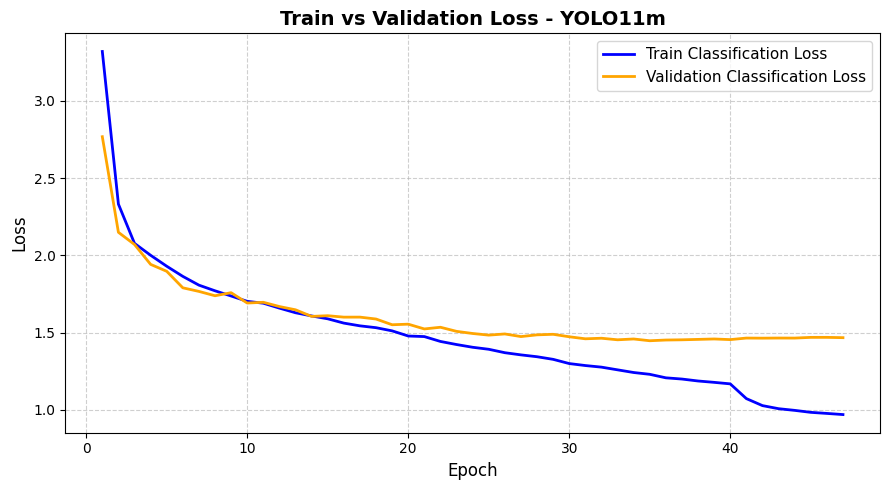

In [42]:
import matplotlib.pyplot as plt

# YOLO11m - Train vs Validation Loss Plot
epochs = yolo11_results_df['epoch']
train_loss = yolo11_results_df['train/cls_loss']
val_loss = yolo11_results_df['val/cls_loss']

plt.figure(figsize=(9, 5))
plt.plot(epochs, train_loss, label='Train Classification Loss', color='blue', linewidth=2)
plt.plot(epochs, val_loss, label='Validation Classification Loss', color='orange', linewidth=2)
plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Loss", fontsize=12)
plt.title("Train vs Validation Loss - YOLO11m", fontsize=14, fontweight='bold')
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


## 2. Compare Model Performances based on Micro-F1:

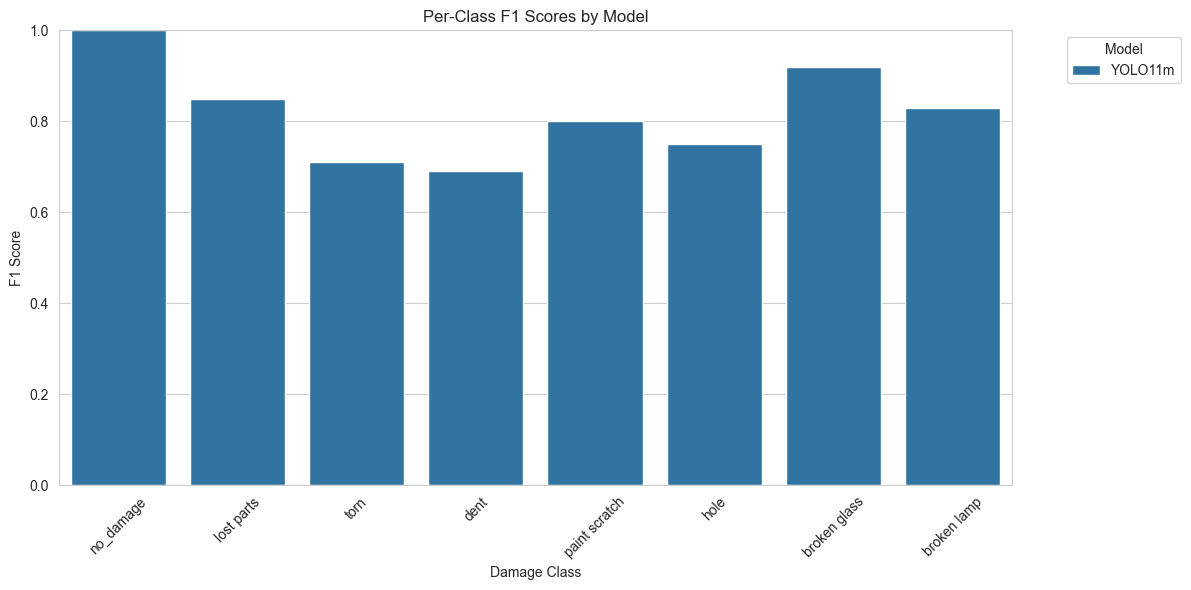

In [43]:
plt.figure(figsize=(12, 6))
sns.set_style("whitegrid")

# Create vertical barplot
sns.barplot(
    data=classwise_results,
    x="Class",
    y="F1 Score",
    hue="Model"
)

# Customize
plt.title("Per-Class F1 Scores by Model")
plt.ylim(0, 1.0)
plt.xlabel("Damage Class")
plt.ylabel("F1 Score")
plt.xticks(rotation=45)
plt.legend(title="Model", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 3. mAP improvement during YOLO model training:

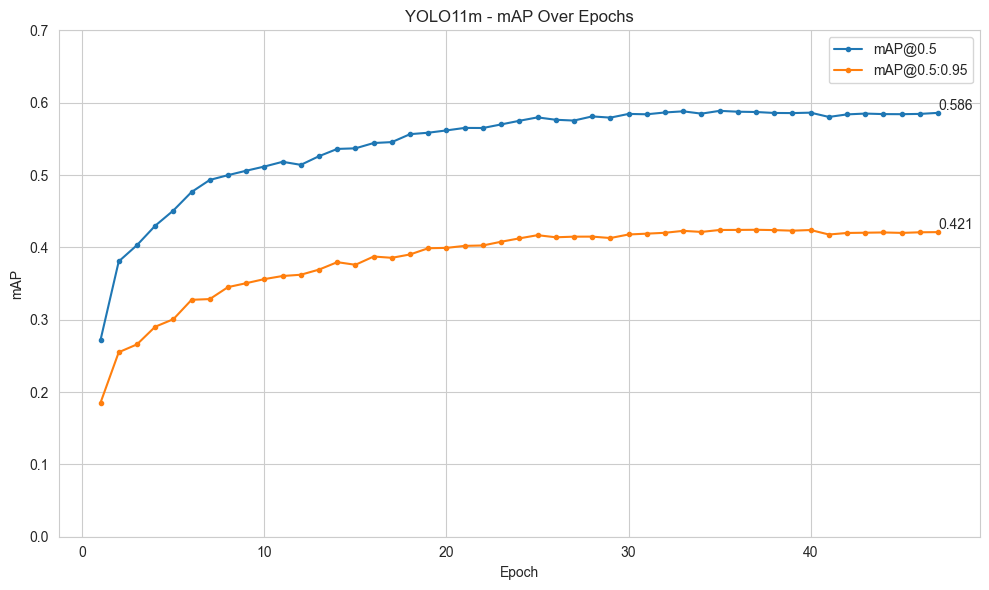

In [44]:
# yolo11_results_df['Epoch'] = range(1, len(yolo11_results_df) + 1)

# Plot mAP curves
plt.figure(figsize=(10, 6))
plt.plot(yolo11_results_df['epoch'], yolo11_results_df['metrics/mAP50(B)'], label='mAP@0.5', marker='.')
plt.plot(yolo11_results_df['epoch'], yolo11_results_df['metrics/mAP50-95(B)'], label='mAP@0.5:0.95', marker='.')

# Annotate final values
plt.text(yolo11_results_df['epoch'].iloc[-1],
         yolo11_results_df['metrics/mAP50(B)'].iloc[-1],
         f"{yolo11_results_df['metrics/mAP50(B)'].iloc[-1]:.3f}",
         ha='left', va='bottom', fontsize=10)

plt.text(yolo11_results_df['epoch'].iloc[-1],
         yolo11_results_df['metrics/mAP50-95(B)'].iloc[-1],
         f"{yolo11_results_df['metrics/mAP50-95(B)'].iloc[-1]:.3f}",
         ha='left', va='bottom', fontsize=10)

# Customize plot
plt.xlabel("Epoch")
plt.ylabel("mAP")
plt.title("YOLO11m - mAP Over Epochs")
plt.ylim(0, 0.7)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


In [47]:
import pandas as pd
from IPython.display import display

# قراءة ملف نتائج تدريب YOLO11m
results_csv_path = WORK_DIR / 'yolo11_results/best_yolo11_model/results.csv'

if results_csv_path.exists():
    df = pd.read_csv(results_csv_path)
    # تنظيف أسماء الأعمدة من المسافات الزائدة
    df.columns = [c.strip() for c in df.columns]
    
    # الحصول على أحدث وأفضل النتائج
    last_row = df.iloc[-1]
    best_row = df.loc[df['metrics/mAP50(B)'].idxmax()]
    
    print("="*55)
    print("🏆 ملخص الدقة النهائي لموديل YOLO11m لمشروع التخرج 🏆")
    print("="*55)
    print(f"🔹 Best mAP@0.50 (أعلى دقة تحديد صدمات) : {best_row['metrics/mAP50(B)'] * 100:.2f}%")
    print(f"🔹 Best mAP@0.50:0.95 (الدقة الصارمة)    : {best_row['metrics/mAP50-95(B)'] * 100:.2f}%")
    print(f"🔹 Precision (نسبة صحة التنبؤات)        : {best_row['metrics/precision(B)'] * 100:.2f}%")
    print(f"🔹 Recall (نسبة اكتشاف كل الصدمات)       : {best_row['metrics/recall(B)'] * 100:.2f}%")
    print("="*55)
else:
    print("ملف النتائج موجود في المسار:", results_csv_path)


🏆 ملخص الدقة النهائي لموديل YOLO11m لمشروع التخرج 🏆
🔹 Best mAP@0.50 (أعلى دقة تحديد صدمات) : 58.87%
🔹 Best mAP@0.50:0.95 (الدقة الصارمة)    : 42.40%
🔹 Precision (نسبة صحة التنبؤات)        : 67.36%
🔹 Recall (نسبة اكتشاف كل الصدمات)       : 57.35%


In [49]:
!zip -r /kaggle/working/yolo_evaluation_plots.zip /kaggle/working/yolo11_results/best_yolo11_model/*.png /kaggle/working/yolo11_results/best_yolo11_model/*.jpg /kaggle/working/yolo11_results/best_yolo11_model/*.csv
print("✅ تم إنشاء ملف yolo_evaluation_plots.zip بنجاح، تقدر تحمله الآن!")


  adding: kaggle/working/yolo11_results/best_yolo11_model/BoxF1_curve.png (deflated 6%)
  adding: kaggle/working/yolo11_results/best_yolo11_model/BoxP_curve.png (deflated 6%)
  adding: kaggle/working/yolo11_results/best_yolo11_model/BoxPR_curve.png (deflated 6%)
  adding: kaggle/working/yolo11_results/best_yolo11_model/BoxR_curve.png (deflated 6%)
  adding: kaggle/working/yolo11_results/best_yolo11_model/confusion_matrix_normalized.png (deflated 16%)
  adding: kaggle/working/yolo11_results/best_yolo11_model/confusion_matrix.png (deflated 17%)
  adding: kaggle/working/yolo11_results/best_yolo11_model/results.png (deflated 8%)
  adding: kaggle/working/yolo11_results/best_yolo11_model/labels.jpg (deflated 21%)
  adding: kaggle/working/yolo11_results/best_yolo11_model/train_batch0.jpg (deflated 4%)
  adding: kaggle/working/yolo11_results/best_yolo11_model/train_batch1.jpg (deflated 4%)
  adding: kaggle/working/yolo11_results/best_yolo11_model/train_batch2.jpg (deflated 3%)
  adding: kaggle